In [ ]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
from Bio import pairwise2
import seaborn as sns
import matplotlib as mpl
from matplotlib import colors as mcolors
import numpy as np
from statistics import mean
import os
import scipy
from matplotlib.colors import ListedColormap
import ast
import matplotlib.ticker as mticker
import figure_style as fs
import statistics

/Users/sarah/git/NguyenLab/.venv/lib/python3.13/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
# Get the data 
path = "../data_files/amplicon_data/GE681B_clones_filtered.xlsx"
pathA = "../data_files/amplicon_data/GE681A_clones.xlsx"
scRNA_bc_path = "../data_files/scRNAseq_bc_response/sample_final_bc_response"

# Get a list of scRNAseq barcode association files
scRNA_bc_files = [f for f in os.listdir(scRNA_bc_path)]

# Read the data into pandas
xls = pd.ExcelFile(path)
xlsA = pd.ExcelFile(pathA)

In [3]:
# Parse Excel file into one big dataframe with all data

# Parse all sheets in excel files into DataFrames and put them into a list
## Set up data structures
dfs = []
names = xls.sheet_names
namesA = xlsA.sheet_names
cohorts = {"U": "Untreated", "C": "Carboplatin", "P": "Paclitaxel"}

## Collect and clean data from primary samples
for i in range(0, 4):
    sheet = xlsA.parse(i, skiprows=[0])[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP', 'var_seq', 'n_reads', 'FRV', 'logFRV', 'cell', 'adjusted','Time (days)', 'Generations', 'Doubling time']]
    sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']] = sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']].ffill()
    sheet["var_seq"] = sheet["var_seq"].apply(lambda x: str(x).strip()).apply(lambda x: x.upper())
    sheet["Tumor"] = namesA[i].strip().split("-")[0]
    sheet["Cohort"] = "Primary"
    sheet["BC"] = 1
    sheet["Mouse"] = sheet.apply(lambda x: x["sample"].split("_")[0], axis = 1)
    mice = sheet["Mouse"].unique()
    mouse_dict = {mouse: idx+1 for idx, mouse in enumerate(mice)}
    sheet["Mouse num"] = sheet["Mouse"].map(mouse_dict)
    sheet["%GFP+"] = sheet.apply(lambda x: x["%GFP+"] * 100 if x["%GFP+"] < 1 else x["%GFP+"], axis = 1)
    sheet["%sequenced"] = sheet.apply(lambda x: x["%sequenced"] * 100 if x["%sequenced"] < 1 else x["%sequenced"], axis = 1)
    dfs.append(sheet)

## Collect and clean data from secondary samples
for i in range(0, len(names)):
    sheet = xls.parse(i, skiprows=[0])[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP', 'var_seq', 'n_reads', 'FRV', 'logFRV', 'cell', 'adjusted', "BC", 'Time (days)', 'Generations', 'Doubling time']]
    sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']] = sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']].ffill()
    sheet["var_seq"] = sheet["var_seq"].apply(lambda x: str(x).strip()).apply(lambda x: x.upper())
    sheet["Tumor"] = names[i].strip().split("-")[0]
    sheet["Cohort"] = cohorts[names[i].strip().split(" ")[-1]]
    sheet["%GFP+"] = sheet.apply(lambda x: x["%GFP+"] * 100 if x["%GFP+"] < 1 else x["%GFP+"], axis = 1)
    sheet["%sequenced"] = sheet.apply(lambda x: x["%sequenced"] * 100 if x["%sequenced"] < 1 else x["%sequenced"], axis = 1)
    sheet["Mouse"] = sheet.apply(lambda x: x["sample"].split("_")[0] if x["sample"][0] == "M" else (x["sample"].split("_")[1] if x["sample"][0:4] == "REDO" else x["sample"].split("_")[2]), axis = 1)
    mice = sheet["Mouse"].unique()
    mouse_dict = {mouse: idx+1 for idx, mouse in enumerate(mice)}
    sheet["Mouse num"] = sheet["Mouse"].map(mouse_dict)
    dfs.append(sheet)

# Join all DataFrames together into one dataset, remove spaces from column names, and remove rows with no adjusted cell count
data = pd.concat(dfs, join="outer", ignore_index=True)
data = data.rename(columns=lambda x: x.strip())
data.dropna(subset=["adjusted"], inplace=True)

# Filter out data from BC2
BC1_data = data.loc[data["BC"] == 1]

In [4]:
# Filter for relevant mice
# List of propagated mice
prop_mice = ["AN21-021161", "AN21-021169", "AN21-021165", "AN21-021162"]
# dataframe with only primary, propagated mice
prop_mice_df = BC1_data.loc[BC1_data["Mouse"].isin(prop_mice)]
# dataframe with only secondary mice
secondary_df = BC1_data.loc[BC1_data["Cohort"] != "Primary"]
# Concatenate the propagated mice and secondary mice dataframe
full_data_unmerged = pd.concat([prop_mice_df, secondary_df], join="outer", ignore_index=True).drop(columns=["sample"])

# Merge any rows with the same barcode within the same sample and recalculate generations, adjusted, and doubling time
grouping_cols = ["Tumor", "Cohort", "Mouse", "var_seq"]
agg_dict = {}
for col in full_data_unmerged.columns:
    if col not in grouping_cols and col not in  ["Doubling time", "adjusted", "Generations"]:
        agg_dict[col] = "first"
agg_dict["cell"] = "sum"
agg_dict["%sequenced"] = "sum"
merged = full_data_unmerged.groupby(grouping_cols).agg(agg_dict).reset_index()
merged["%sequenced"] = merged.groupby(["Tumor", "Cohort", "Mouse"])["%sequenced"].transform("max")
merged["adjusted"] = merged["cell"] * (100 / merged["%sequenced"])
merged["Generations"] = np.log10(merged["adjusted"]) / np.log10(2)
merged["Doubling time"] = merged["Time (days)"] / merged["Generations"]
full_data_unmerged = merged

In [ ]:
# Set up a dataframe that looks at individual BC1 barcode sequences 
    # and says at a glance which mice they were found in, how many were found, and doubling time

# Set up dataframe with each unique barcode and the model it was found in, in only propagated primary and secondary cohorts
unique_seqs = full_data_unmerged.drop_duplicates(subset=["var_seq"])["var_seq"]
secondary_cohorts = ["Untreated", "Carboplatin", "Paclitaxel"]

# Set up a list to hold all the data
num_clones_BC1_v2 = []

# Iterate through each unique sequence found in the model
for seq in unique_seqs:
    seq_data = {("", "Sequence"): seq}
    # Iterate through each tumour 
    for model in full_data_unmerged["Tumor"].unique():
        # Set up a dictionary to hold data for each sequence, and instantiate with values
        # each seq will be a row in the final dataframe
        seq_data[(model, "Primary")] = 0
        for cohort in secondary_cohorts:
            for i in range(1, 4):
                seq_data[(model, f"{cohort} {i}")] = 0
    # Iterate through each row in the original dataframe from the model from the mouse
    # (the relevant columns this has are var_seq, adjusted (cell count), Cohort, Mouse num, Tumour)
    for index, row in full_data_unmerged.iterrows():
        # Compare current sequence to sequence in the row
        score = pairwise2.align.globalms(seq, row["var_seq"], 1, 0, -1, -1, score_only=True)
        # If matches, collect data from the row
        # NOTE: if any sequences are recorded more than once in the same mouse (ie for repeat runs etc)
            # the last set of values will replace any previous values
        if score == 31:
            if row["Cohort"] != "Primary":
                seq_data[(f"{row['Tumor']}", f"{row['Cohort']} {row['Mouse num']}")] = round(row["adjusted"], 2)
            else:
                seq_data[(f"{row['Tumor']}", f"{row['Cohort']}")] = round(row["adjusted"], 2)
    num_clones_BC1_v2.append(seq_data)


In [6]:
# Convert list of dictionaries with seq and number of clones for each seq in ALL models to dataframe
seq_cols = pd.MultiIndex.from_tuples([x for x in num_clones_BC1_v2[0].keys()])
seq_info = pd.DataFrame(num_clones_BC1_v2, columns=seq_cols)
seq_info = seq_info.set_index(("", "Sequence"), drop=True)
seq_info.index.name = "Sequence"

In [ ]:
# Characterize each clone as diminished, minimal change, expanded and add to the full dataframe - including propagating primary clones

# Create columns in full dataset for Response to treatment and Consistency and prep data structures
full_data_unmerged["Treated Response"] = ""
full_data_unmerged["Treated Response Consistency"] = ""
full_data_unmerged["Untreated Carboplatin Response"] = ""
full_data_unmerged["Untreated Paclitaxel Response"] = ""
full_stats = {}

clonal_comp_for_bargraph_treated_response = {}
clonal_comp_for_bargraph_treated_response_primary = {}

# Barcodes detected in each model, for the per-sample totals below
valid_barcodes_per_model = {}

# Set cutoffs for Expanded and Diminished clones
expanded_cutoff = 30
diminished_cutoff = -30

for model in full_data_unmerged["Tumor"].unique():
    tumor_seq_info = seq_info[model]
    tumor_seq_info = tumor_seq_info.loc[(tumor_seq_info!=0).any(axis=1)]
    valid_barcodes_per_model[model] = tumor_seq_info.index.tolist()
    model_info = []

    for index, row in tumor_seq_info.iterrows():
        # Set up dict to hold info about bc row
        row_meta = {"barcode info": {
                        "barcode": index,
                        "primary_cells": 0,
                        "secondary_presence": 0,
                        "primary_proportion": 0
                    },
                    "secondary cohort info": {
                        cohort: {
                            "all_num_cells": [],
                            "all_proportions": [],
                            "mouse": [],
                            "nonzero_num_cells": [],
                            "presence": 0,
                            "avg_nonzero": 0,
                            "all_treated_responses": [],
                            "all_untreated_Carboplatin_responses": [],
                            "all_untreated_Paclitaxel_responses": []
                        } for cohort in ["Untreated", "Carboplatin", "Paclitaxel"]}}
        row_cohort = row_meta["secondary cohort info"]
        row_bc = row_meta["barcode info"]

        # Collect number of cells in each treated cohort for given barcode and replicates it's present in for each cohort
        for column, value in row.items():
            cohort = str(column).split(" ")[0]
            if cohort == "Primary":
                row_bc["primary_cells"] = value
            else:
                mouse_num = str(column).split(" ")[1]
                row_cohort[cohort]["all_num_cells"].append(value)
                row_cohort[cohort]["mouse"].append(mouse_num)
                if value > 0:
                    row_bc["secondary_presence"] += 1
                    row_cohort[cohort]["nonzero_num_cells"].append(value)
                    row_cohort[cohort]["presence"] += 1

        # Calculate average nonzero cell numbers
        for cohort in row_cohort.keys():
            if row_cohort[cohort]["presence"] > 0:
                row_cohort[cohort]["avg_nonzero"] = mean(row_cohort[cohort]["nonzero_num_cells"])

        # Classify clones per replicate with a response to treatment
        for cohort in row_cohort.keys():
            for i in range(0,3):
                curr_num_cells = row_cohort[cohort]["all_num_cells"][i]

                # Deal with untreated
                if cohort == "Untreated":
                    # Classify as not present or generic "Untreated"
                    if curr_num_cells > 0:
                        curr_response = "Untreated"
                    else:
                        curr_response = "Not present"

                # Deal with treated
                else:
                    # Classify individual clone/ replicate pairs as Diminished, Minimal change, Expanded, or Not present (where not present means not present in individual treated mouse)
                    if curr_num_cells == 0 and row_cohort["Untreated"]["presence"] > 0:
                        curr_response = "Not present"
                    elif row_cohort["Untreated"]["presence"] == 0 and curr_num_cells == 0:
                        curr_response = "Not present"
                    elif row_cohort["Untreated"]["presence"] > 0:
                        curr_change = ((curr_num_cells - row_cohort["Untreated"]["avg_nonzero"])/row_cohort["Untreated"]["avg_nonzero"])*100
                        if curr_change <= diminished_cutoff:
                            curr_response = "Diminished"
                        elif diminished_cutoff < curr_change < expanded_cutoff:
                            curr_response = "Minimal change"
                        elif curr_change >= expanded_cutoff:
                            curr_response = "Expanded"
                    elif row_cohort["Untreated"]["presence"] == 0 and curr_num_cells > 0:
                        curr_response = "Expanded"

                    if cohort == "Carboplatin":
                        row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append(curr_response)
                        if curr_response != "Not present":
                            row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append("Carboplatin")
                        elif curr_response == "Not present":
                            row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append("Not present")
                    elif cohort == "Paclitaxel":
                        row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append(curr_response)
                        if curr_response != "Not present":
                            row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append("Paclitaxel")
                        elif curr_response == "Not present":
                            row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append("Not present")

                    full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort) & (full_data_unmerged["Mouse num"] == int(row_cohort[cohort]["mouse"][i]))), f"Untreated {cohort} Response"] = curr_response

                row_cohort[cohort]["all_treated_responses"].append(curr_response)

                if curr_num_cells > 0:
                    full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort) & (full_data_unmerged["Mouse num"] == int(row_cohort[cohort]["mouse"][i]))), "Treated Response"] = curr_response

            # Record consistency to the barcode for each secondary cohort
            cohort_responses = [response for response in row_cohort[cohort]["all_treated_responses"] if response != "Not present"]
            if row_cohort[cohort]["presence"] == 1:
                consistency = "1 Replicate"
            else:
                if len(set(cohort_responses)) > 1:
                    consistency = "Inconsistent"
                else:
                    consistency = "Consistent"
            full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort)), "Treated Response Consistency"] = consistency

        # Classify untreated clones with regards to each treated cohort and add to row_cohort and full_data_unmerged
        for i in range(0,3):
            curr_num_cells = row_cohort["Untreated"]["all_num_cells"][i]
            carb_responses = row_cohort["Carboplatin"]["all_treated_responses"]
            pac_responses = row_cohort["Paclitaxel"]["all_treated_responses"]

            untreated_carb_response = "Not Set"
            untreated_pac_response = "Not Set"

            if curr_num_cells == 0:
                untreated_carb_response = "Not present"
                untreated_pac_response = "Not present"
            else:
                # Carb response
                if "Expanded" in carb_responses and "Diminished" in carb_responses:
                    untreated_carb_response = "Discrepant"
                elif "Expanded" in carb_responses:
                    untreated_carb_response = "Expanded"
                elif "Diminished" in carb_responses:
                    untreated_carb_response = "Diminished"
                elif "Minimal change" in carb_responses:
                    untreated_carb_response = "Minimal change"
                elif "Not present" in carb_responses and len(set(carb_responses)) == 1:
                    untreated_carb_response = "Diminished"
                # Pac response
                if "Expanded" in pac_responses and "Diminished" in pac_responses:
                    untreated_pac_response = "Discrepant"
                elif "Expanded" in pac_responses:
                    untreated_pac_response = "Expanded"
                elif "Diminished" in pac_responses:
                    untreated_pac_response = "Diminished"
                elif "Minimal change" in pac_responses:
                    untreated_pac_response = "Minimal change"
                elif "Not present" in pac_responses and len(set(pac_responses)) == 1:
                    untreated_pac_response = "Diminished"

                full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == "Untreated") & (full_data_unmerged["Mouse num"] == int(row_cohort["Untreated"]["mouse"][i]))), "Untreated Carboplatin Response"] = untreated_carb_response

                full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == "Untreated") & (full_data_unmerged["Mouse num"] == int(row_cohort["Untreated"]["mouse"][i]))), "Untreated Paclitaxel Response"] = untreated_pac_response

            row_cohort["Untreated"]["all_untreated_Carboplatin_responses"].append(untreated_carb_response)
            row_cohort["Untreated"]["all_untreated_Paclitaxel_responses"].append(untreated_pac_response)

        # Add row data to model stats list
        model_info.append(row_meta)

    # Add model stats to full stats dict
    full_stats[model] = model_info

# Add Primary responses ("Primary"), opposite cohort responses, and save full dataset with responses
## amplicon_full_dataset.csv is read by Parse_barcodes_for_scRNAseq.ipynb (the scRNAseq clone calls)
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Treated Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Untreated Carboplatin Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Untreated Paclitaxel Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Paclitaxel", "Untreated Carboplatin Response"] = "Paclitaxel"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Carboplatin", "Untreated Paclitaxel Response"] = "Carboplatin"
full_data_unmerged.rename(columns={"adjusted": "Clone Size"}, inplace=True)
full_data_unmerged.to_csv("../data_files/amplicon_data/amplicon_full_dataset.csv", index=False)

# Check for scRNAseq-adjusted multi-integration sets of barcodes, update full_data, full_stats and seq_info if they exist,
## and save the corrected full dataset and clone sizes
full_data = full_data_unmerged.copy()

for model in full_data["Tumor"].unique():
    multi_int_file = f"../data_files/scRNAseq_bc_response/multi-integrated_bcs/{model}_final_bc_multi-integration_sets.xlsx"
    if os.path.exists(multi_int_file):
        multi_int_sets = pd.read_excel(multi_int_file)

        # Aggregate a complete set of all barcodes to remove for this model.
        all_barcodes_to_remove = set()
        for i, row in multi_int_sets.iterrows():
            barcode_set_list = ast.literal_eval(row["barcode set"])
            final_barcode = row["final barcode"]
            # Add all barcodes from the set that are not the designated 'final barcode'
            barcodes_to_add = {bc for bc in barcode_set_list if bc != final_barcode}
            all_barcodes_to_remove.update(barcodes_to_add)

        # If we found barcodes to remove, filter full_stats, full_data, and seq_info ONCE.
        if all_barcodes_to_remove:
            # Safely filter the full_stats[model] list using a list comprehension.
            # This creates a new list containing only the items we want to keep.
            full_stats[model] = [
                d for d in full_stats[model]
                if d["barcode info"]["barcode"] not in all_barcodes_to_remove
            ]

            # Filter the full_data DataFrame in a single, efficient operation.
            rows_to_drop = (full_data.Tumor == model) & (full_data.var_seq.isin(all_barcodes_to_remove))
            full_data = full_data.drop(full_data[rows_to_drop].index)

            # Find which barcodes to remove are actually in seq_info index
            barcodes_in_index = seq_info.index.intersection(all_barcodes_to_remove)

            if not barcodes_in_index.empty:
                # Identify all columns that belong to the current model
                model_specific_cols = [col for col in seq_info.columns if col[0] == model]

                # For the identified barcodes, set the values in the model-specific columns to 0
                seq_info.loc[barcodes_in_index, model_specific_cols] = 0

full_data.to_csv("../data_files/amplicon_data/amplicon_full_dataset_multi-int_corrected.csv", index=False)
seq_info.to_excel("../data_files/amplicon_data/clone_size_each_mouse_multi-int_corrected.xlsx")
for model in ["AB040", "IC07", "STG139", "STG201"]:
    model_seq_info = seq_info[model]
    model_seq_info[model_seq_info.ne(0.0).any(axis=1)].to_excel(f"../data_files/amplicon_data/{model}_clone_size_each_mouse_multi-int_corrected.xlsx")

# Get the correct total cell counts for each sample from the updated full_data
totals_per_sample = {}
for model in full_data["Tumor"].unique():
    totals_per_sample[model] = {}
    model_df = full_data[
        (full_data["Tumor"] == model) &
        (full_data["var_seq"].isin(valid_barcodes_per_model[model]))
    ].copy()

    # Create a unique sample identifier to group by
    model_df['Sample'] = model_df['Cohort']
    secondary_mask = model_df['Cohort'] != 'Primary'
    model_df.loc[secondary_mask, 'Sample'] = model_df.loc[secondary_mask, 'Cohort'] + " " + model_df.loc[secondary_mask, 'Mouse num'].astype(str)

    # Calculate totals and store them
    sample_totals = model_df.groupby('Sample')['Clone Size'].sum()
    totals_per_sample[model] = sample_totals.to_dict()

# Now, loop through the existing full_stats dictionary to populate it with the correct proportions
for model in full_stats.keys():
    model_totals = totals_per_sample.get(model, {})
    for row_meta in full_stats[model]:
        row_bc = row_meta["barcode info"]
        row_cohort = row_meta["secondary cohort info"]

        # Calculate and add primary proportion
        primary_total = model_totals.get("Primary", 0)
        if primary_total > 0:
            row_bc["primary_proportion"] = (row_bc["primary_cells"] / primary_total) * 100
        else:
            row_bc["primary_proportion"] = 0

        # Calculate and add secondary proportions
        for cohort in row_cohort.keys():
            row_cohort[cohort]["all_proportions"] = []

            for i, num_cells in enumerate(row_cohort[cohort]["all_num_cells"]):
                mouse_num = row_cohort[cohort]["mouse"][i]
                sample_name = f"{cohort} {mouse_num}"
                total = model_totals.get(sample_name, 0)

                if total > 0:
                    proportion = (num_cells / total) * 100
                else:
                    proportion = 0

                row_cohort[cohort]["all_proportions"].append(proportion)

# Construct dictionaries of clonal composition for the figures (proportions are now correct)
for model in full_stats.keys():
    model_info = full_stats[model]

    model_clonal_comp = []
    model_clonal_comp_primary = []

    for item in model_info:
        if item["barcode info"]["primary_cells"] > 0:
            prim_comp = {
                "Cohort": "Primary",
                "Mouse": 1,
                "Barcode": item["barcode info"]["barcode"],
                "Cell counts": item["barcode info"]["primary_cells"],
                "Percent": item["barcode info"]["primary_proportion"],
                "Response": "Primary"
            }
            model_clonal_comp_primary.append(prim_comp)

        if item["barcode info"]["secondary_presence"] > 0:
            for cohort in item["secondary cohort info"].keys():
                cohort_info = item["secondary cohort info"][cohort]
                for i in range(0, 3):
                    curr_cells = cohort_info["all_num_cells"][i]
                    if curr_cells > 0:
                        mouse_comp_dict = {
                                "Cohort": cohort,
                                "Mouse": int(cohort_info["mouse"][i]),
                                "Barcode": item["barcode info"]["barcode"],
                                "Cell counts": curr_cells,
                                "Percent": cohort_info["all_proportions"][i],
                                "Response": cohort_info["all_treated_responses"][i]
                            }
                        model_clonal_comp_primary.append(mouse_comp_dict)
                        model_clonal_comp.append(mouse_comp_dict)

    # Add to full clonal composition dicts
    clonal_comp_for_bargraph_treated_response[model] = model_clonal_comp
    clonal_comp_for_bargraph_treated_response_primary[model] = model_clonal_comp_primary

In [ ]:
# Response classification at each percent-change cutoff, for the Muller plots 
response_cutoffs = {"±20%": (20, 20), "±30%": (30, 30), "±40%": (40, 40)}
notebook_cutoff = "±30%"
assert response_cutoffs[notebook_cutoff] == (-diminished_cutoff, expanded_cutoff), "notebook_cutoff must match the classification cell"

def classify_treated_clone(num_cells, untreated_presence, untreated_avg, lower, upper):
    # One clone in one treated mouse; None if the clone is in neither this mouse nor any untreated mouse
    if num_cells == 0:
        return "Not present" if untreated_presence > 0 else None
    if untreated_presence == 0:
        return "Expanded"                           
    change = (num_cells - untreated_avg) / untreated_avg * 100
    if change <= -lower:
        return "Diminished"
    if change >= upper:
        return "Expanded"
    return "Minimal change"

def classify_untreated_clone(treated_responses):
    # One untreated clone against one drug, from its responses in that drug's mice 
    if "Expanded" in treated_responses and "Diminished" in treated_responses:
        return "Discrepant"
    for response in ["Expanded", "Diminished", "Minimal change"]:
        if response in treated_responses:
            return response
    return "Diminished"                             

# At the notebook's cutoff, every call must match the classification cell's own
lower, upper = response_cutoffs[notebook_cutoff]
mismatches = []
for model, model_info in full_stats.items():
    for item in model_info:
        row_cohort = item["secondary cohort info"]
        untreated = row_cohort["Untreated"]
        for drug in ["Paclitaxel", "Carboplatin"]:
            responses = [classify_treated_clone(row_cohort[drug]["all_num_cells"][i], untreated["presence"],
                                                untreated["avg_nonzero"], lower, upper) for i in range(0, 3)]
            for i, response in enumerate(responses):
                if response is not None and response != row_cohort[drug]["all_treated_responses"][i]:
                    mismatches.append((model, drug, i, response, row_cohort[drug]["all_treated_responses"][i]))
            untreated_response = classify_untreated_clone(responses)
            for i in range(0, 3):
                if untreated["all_num_cells"][i] > 0 and untreated_response != untreated[f"all_untreated_{drug}_responses"][i]:
                    mismatches.append((model, f"Untreated vs {drug}", i, untreated_response, untreated[f"all_untreated_{drug}_responses"][i]))
assert not mismatches, mismatches[:5]

saved fig2C_amplicon_muller_clonal_response_composition_pm30: 2.806 x 3.827 in


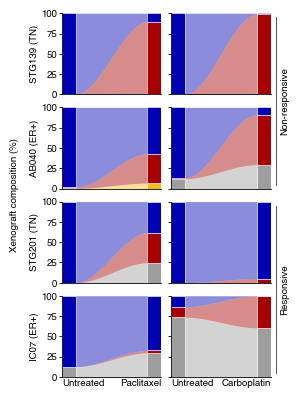

saved fig2C_legend_responses: 0.847 x 0.505 in


<Figure size 84.7x50.5 with 0 Axes>

saved figEV2A_amplicon_muller_clonal_response_composition_symmetric_cutoffs: 4.234 x 2.606 in


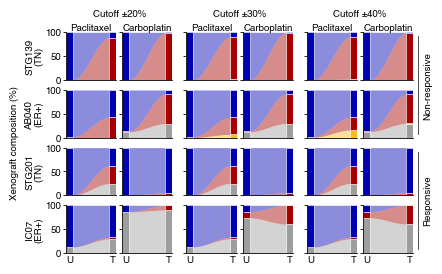

saved figEV2A_legend_responses: 0.850 x 0.482 in


<Figure size 85x48.2 with 0 Axes>

In [ ]:
# Two-timepoint Muller plots of clonal response composition, untreated to each treatment
sns.reset_defaults()
fs.apply_style()

muller_classes =["Other", "Minimal change", "Expanded", "Diminished"]  
muller_colours = {"Diminished": "#0000b3", "Expanded": "#a70000", "Minimal change": "#F5BE19", "Other": "#9e9e9e"}
muller_model_order = ["STG139", "AB040", "STG201", "IC07"]
response_groups = {"Non-responsive": ["STG139", "AB040"], "Responsive": ["STG201", "IC07"]}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
MULLER_BAR_WIDTH = 0.14

def clonal_cell_composition_per_mouse(lower, upper):
    # % of each mouse's cells in each clonal response, per model, drug and bar
    rows = []
    for model, model_info in full_stats.items():
        for item in model_info:
            row_cohort = item["secondary cohort info"]
            untreated = row_cohort["Untreated"]
            for drug in ["Paclitaxel", "Carboplatin"]:
                calls = [classify_treated_clone(row_cohort[drug]["all_num_cells"][i], untreated["presence"],
                                                untreated["avg_nonzero"], lower, upper) for i in range(0, 3)]
                if all(call is None for call in calls):
                    continue                    # in neither the untreated mice nor this drug's mice
                response = classify_untreated_clone(calls)
                response = "Other" if response == "Discrepant" else response
                for bar, cohort in [("Untreated", "Untreated"), ("Treated", drug)]:
                    for num_cells, mouse in zip(row_cohort[cohort]["all_num_cells"], row_cohort[cohort]["mouse"]):
                        if model == "STG139" and cohort == "Untreated" and str(mouse) == "3":
                            continue
                        rows.append({"Tumor": model, "Drug": drug, "Bar": bar, "Mouse": str(mouse), "Response": response, "Cells": num_cells})
    per_mouse = pd.DataFrame(rows).pivot_table(index=["Tumor", "Drug", "Bar", "Mouse"], columns="Response", values="Cells",
                                               aggfunc="sum", fill_value=0).reindex(columns=muller_classes, fill_value=0)
    return per_mouse.div(per_mouse.sum(axis=1), axis=0) * 100

def clonal_cell_composition(lower, upper):
    # Mean over each cohort's mice of the % of the mouse's cells in each clonal response, per model and drug
    composition = clonal_cell_composition_per_mouse(lower, upper).groupby(level=["Tumor", "Drug", "Bar"]).mean()
    return composition.stack().rename_axis(["Tumor", "Drug", "Bar", "Response"]).unstack("Bar")[["Untreated", "Treated"]]

def draw_muller(ax, left, right):
    # left, right: % per response (muller_classes order) for the untreated and treated bars
    left_edges, right_edges = np.concatenate([[0], np.cumsum(left)]), np.concatenate([[0], np.cumsum(right)])
    x = np.linspace(MULLER_BAR_WIDTH, 1 - MULLER_BAR_WIDTH, 200)
    t = (x - x[0]) / (x[-1] - x[0])
    ease = t * t * (3 - 2 * t)          # smoothstep: flat where the bands leave and join the bars
    for k, cls in enumerate(muller_classes):
        low = left_edges[k] + (right_edges[k] - left_edges[k]) * ease
        high = left_edges[k + 1] + (right_edges[k + 1] - left_edges[k + 1]) * ease
        ax.fill_between(x, low, high, color=muller_colours[cls], alpha=0.45, linewidth=0)
        for x_bar, heights, edges in [(MULLER_BAR_WIDTH / 2, left, left_edges), (1 - MULLER_BAR_WIDTH / 2, right, right_edges)]:
            ax.bar(x_bar, heights[k], bottom=edges[k], width=MULLER_BAR_WIDTH, color=muller_colours[cls], edgecolor="white", linewidth=0.4)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 100)

compositions = {cutoff: clonal_cell_composition(lower, upper) for cutoff, (lower, upper) in response_cutoffs.items()}
with pd.ExcelWriter("../data_files/amplicon_data/amplicon_muller_clonal_response_cell_composition.xlsx") as writer:
    for cutoff, composition in compositions.items():
        composition.round(2).to_excel(writer, sheet_name=cutoff.replace("/", "-"))

def muller_response_brackets(fig, axes_column, x):
    # Non-responsive / Responsive brackets down the right-hand side, beside the given column of panels, at x inches
    fig_w, fig_h = fig.get_size_inches()
    for group, members in response_groups.items():
        rows = [muller_model_order.index(m) for m in members]
        group_top = axes_column[min(rows)].get_position().y1
        group_bottom = axes_column[max(rows)].get_position().y0
        fig.add_artist(mpl.lines.Line2D([x / fig_w] * 2, [group_bottom + 0.04 / fig_h, group_top - 0.04 / fig_h],
                                        color="#333333", linewidth=fs.LINE, transform=fig.transFigure))
        fig.text((x + 0.05) / fig_w, (group_top + group_bottom) / 2, group, rotation=90, va="center", ha="left")

def muller_legend(name, width, height):
    # The response colours, as a panel of its own
    handles = [mpl.patches.Patch(color=muller_colours[cls], label=cls) for cls in reversed(muller_classes)]
    fs.legend_panel(name, width, height, handles, loc="center left", handlelength=0.8, handleheight=0.8,
                    labelspacing=0.25)
    plt.show()

def draw_muller_one_cutoff(composition, width=2.806, height=3.827):
    # One cutoff: a row per model, Paclitaxel and Carboplatin side by side
    left, right, top, bottom, column_gap, row_gap = 0.52, 0.2, 0.05, 0.14, 0.1, 0.13
    fig = fs.new_panel(width, height)
    panel_w = (width - left - right - column_gap) / 2
    panel_h = (height - top - bottom - (len(muller_model_order) - 1) * row_gap) / len(muller_model_order)
    axes = fs.inch_grid(fig, left, top, len(muller_model_order), 2, panel_w, panel_h, column_gap, row_gap)
    for r, model in enumerate(muller_model_order):
        for c, drug in enumerate(["Paclitaxel", "Carboplatin"]):
            ax = axes[r, c]
            panel = composition.loc[(model, drug)].reindex(muller_classes, fill_value=0)
            draw_muller(ax, panel["Untreated"].values, panel["Treated"].values)
            ax.set_xticks([0, 1])
            if r == len(muller_model_order) - 1:
                ax.set_xticklabels(["Untreated", drug])
                ax.get_xticklabels()[0].set_horizontalalignment("left")
                ax.get_xticklabels()[1].set_horizontalalignment("right")
            else:
                ax.set_xticklabels([])
            ax.tick_params(axis="x", length=0)
            ax.set_yticks([0, 25, 50, 75, 100])
            ax.tick_params(axis="y", labelleft=(c == 0))
            ax.spines[["top", "right"]].set_visible(False)
        axes[r, 0].set_ylabel(f"{model} ({model_type[model]})", labelpad=1.5)
    fs.fig_text(fig, 0.0, top + (height - top - bottom) / 2, "Xenograft composition (%)", rotation=90,
                ha="left", va="center")
    muller_response_brackets(fig, axes[:, 1], width - right + 0.05)
    return fig

fig = draw_muller_one_cutoff(compositions["±30%"])
fs.save_panel(fig, "fig2C_amplicon_muller_clonal_response_composition_pm30")
plt.show()
muller_legend("fig2C_legend_responses", 0.847, 0.505)

# Figure 2C source data: a row per band (model, drug, clonal response, top of the stack first, as in the legend) with its
#   height in the untreated and treated bars, and the % of each mouse's cells that those heights average
per_mouse = clonal_cell_composition_per_mouse(*response_cutoffs["±30%"]).stack().unstack(["Bar", "Mouse"])
per_mouse = per_mouse.reindex(columns=[(bar, mouse) for bar in ["Untreated", "Treated"] for mouse in ["1", "2", "3"]])
per_mouse.columns = [f"{bar} {mouse} (%)" for bar, mouse in per_mouse.columns]
fig2C_data = compositions["±30%"].rename(columns=lambda bar: f"{bar} bar (%)").join(per_mouse)
fig2C_data = fig2C_data.reindex(pd.MultiIndex.from_product(
    [muller_model_order, ["Paclitaxel", "Carboplatin"], list(reversed(muller_classes))],
    names=["Model", "Drug", "Clonal response"])).reset_index()
fig2C_data.insert(1, "Subtype", fig2C_data["Model"].map(model_type))
fig2C_data.insert(2, "Model responsiveness", fig2C_data["Model"].map({m: g for g, ms in response_groups.items() for m in ms}))
fig2C_data.to_csv("../data_files/amplicon_data/fig2C_amplicon_muller_clonal_response_composition_pm30.csv", index=False)

def draw_muller_cutoffs_side_by_side(cutoffs, panel, width=4.234, height=2.606):
    # The chosen cutoffs side by side, each block laid out as the single-cutoff figure, at the panel's size on the page
    left, right, top, bottom = 0.56, 0.2, 0.25, 0.15
    in_block_gap, block_gap, row_gap = 0.06, 0.14, 0.1
    fig = fs.new_panel(width, height)
    panel_w = (width - left - right - len(cutoffs) * in_block_gap - (len(cutoffs) - 1) * block_gap) / (2 * len(cutoffs))
    panel_h = (height - top - bottom - (len(muller_model_order) - 1) * row_gap) / len(muller_model_order)
    block_axes = []
    for b, cutoff in enumerate(cutoffs):
        composition = compositions[cutoff]
        block_left = left + b * (2 * panel_w + in_block_gap + block_gap)
        axes = fs.inch_grid(fig, block_left, top, len(muller_model_order), 2, panel_w, panel_h, in_block_gap, row_gap)
        for r, model in enumerate(muller_model_order):
            for c, drug in enumerate(["Paclitaxel", "Carboplatin"]):
                ax = axes[r, c]
                panel_data = composition.loc[(model, drug)].reindex(muller_classes, fill_value=0)
                draw_muller(ax, panel_data["Untreated"].values, panel_data["Treated"].values)
                ax.set_xticks([MULLER_BAR_WIDTH / 2, 1 - MULLER_BAR_WIDTH / 2])     # the two bars' centres
                ax.set_xticklabels(["U", "T"] if r == len(muller_model_order) - 1 else [])
                ax.tick_params(axis="x", length=0)
                ax.set_yticks([0, 50, 100])
                ax.tick_params(axis="y", labelleft=(b == 0 and c == 0))
                ax.spines[["top", "right"]].set_visible(False)
                if r == 0:
                    ax.set_title(drug, pad=1.5)
            if b == 0:
                axes[r, 0].set_ylabel(f"{model}\n({model_type[model]})", labelpad=1.5, linespacing=1.0)
        block_axes.append(axes)
        fs.fig_text(fig, block_left + panel_w + in_block_gap / 2, 0.02, f"Cutoff {cutoff}", ha="center", va="top")
    fs.fig_text(fig, 0.0, top + (height - top - bottom) / 2, "Xenograft composition (%)", rotation=90, ha="left",
                va="center")
    muller_response_brackets(fig, block_axes[-1][:, 1], width - right + 0.05)
    fs.save_panel(fig, panel)
    plt.show()

draw_muller_cutoffs_side_by_side(list(compositions), "figEV2A_amplicon_muller_clonal_response_composition_symmetric_cutoffs")
muller_legend("figEV2A_legend_responses", 0.85, 0.482)

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]


/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:115: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int).astype(float), cmap=colormap_response, ax=axes[1],
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:117: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int).astype(float), cmap=colormap_RNA, ax=axes[2],
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:115: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int).astype(float), cmap=colormap_response, ax=axes[1],
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:117: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int).astype(float), cmap=colormap_RNA, ax=axes[2],
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1543696300.py:117: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int).astype(float), cmap=colormap_RNA, ax=axes[2],


saved figS2_amplicon_clonalComposition_responseToTreatment_scRNAseqPresence: 7.766 x 9.831 in


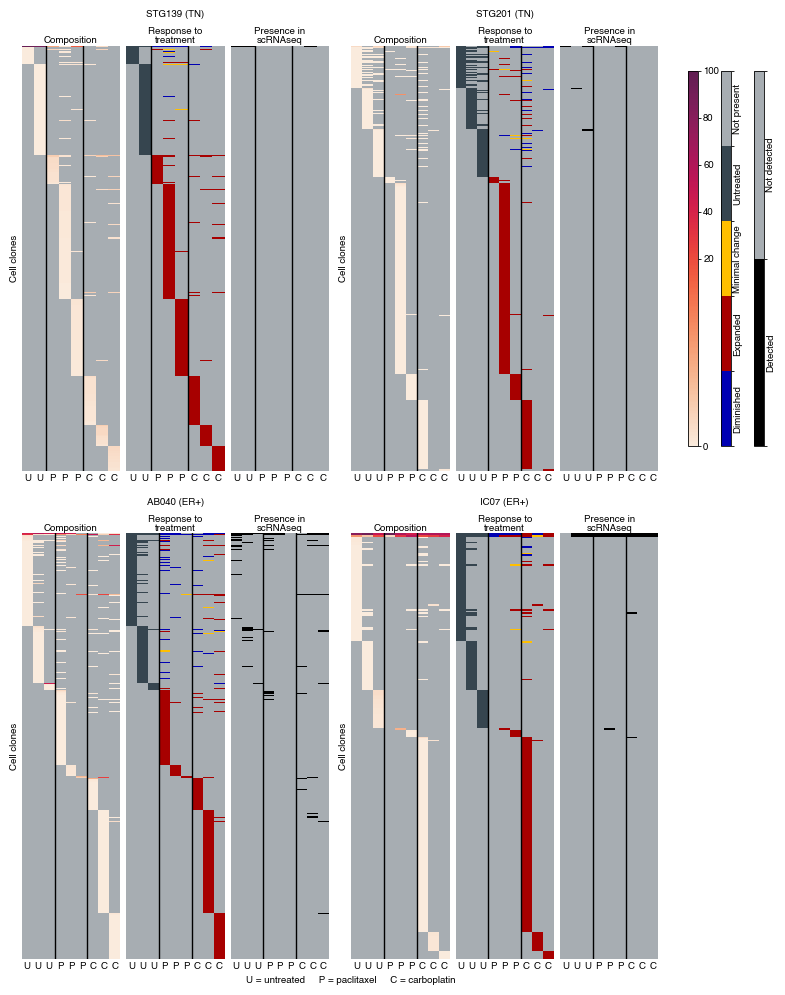

In [ ]:
# Graph heatmaps of shared and all barcodes in each tumor by the percent they make up in the tumor
# Set up dictionary to associate mouse designations with arbitrary mouse numbers (1-3)
mice = full_data.drop_duplicates(subset=["Mouse"])
mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]
mice = mice[["Sample", "Mouse num"]].set_index("Sample").rename_axis(None, axis=1).to_dict()["Mouse num"]
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

sns.reset_defaults()
fs.apply_style()

# Iterate through models, collecting each model's three heatmap tables
heatmap_data = {}
for key, val in clonal_comp_for_bargraph_treated_response.items():
    # Set up data structure with percent composition and response to treatment
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    df = df.sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    df["Cohort mouse"] = df["Cohort"] + " " + df["Mouse"].astype("str")

    # Get scRNAseq barcodes
    df["scRNAseq"] = "Not Detected"
    for file in scRNA_bc_files:
        file_split = file.split("_")
        if file_split[0] == key:
            cohort_mouse = f'{file_split[2]} {mice["_".join(file_split[0:3])]}'
            temp_df = pd.read_csv(f"{scRNA_bc_path}/{file}")
            temp_df = temp_df.loc[temp_df["barcode"] != "None"].drop_duplicates(subset=["barcode"])
            bcs = temp_df["barcode"].dropna().tolist()
            if len(bcs) > 0:
                for barcode in bcs:
                    for i, row in df.iterrows():
                        if row["Barcode"] == barcode and row["Cohort mouse"] == cohort_mouse:
                            df.at[i, "scRNAseq"] = "Detected"
    # Set up data structures and organize
    pivot_df = df[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = pivot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)

    pivot_response = df[["Cohort mouse", "Barcode", "Response"]]
    pivot_response = pivot_response.pivot(index='Barcode', columns='Cohort mouse', values='Response').fillna("Not Present")

    pivot_RNApresence = df[["Cohort mouse", "Barcode", "scRNAseq"]]
    pivot_RNApresence = pivot_RNApresence.pivot(index='Barcode', columns='Cohort mouse', values='scRNAseq').fillna("Not Detected")

    # Sort percent dataframe and merge with the others so they're sorted too
    if key != "STG139":
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    else:
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)

    ordered_responses = pd.merge(pivot_df, pivot_response, how="inner", left_index=True, right_index=True)

    ordered_scRNA = pd.merge(pivot_df, pivot_RNApresence, how="inner", left_index=True, right_index=True)
    
    if key == "STG139":
        percent_comp = ordered_responses[['Untreated 1_x', 'Untreated 2_x', 'Paclitaxel 1_x', 'Paclitaxel 2_x', 'Paclitaxel 3_x', 'Carboplatin 1_x', 'Carboplatin 2_x', 'Carboplatin 3_x']]
        percent_comp = percent_comp.rename(columns = {'Untreated 1_x': "Untreated 1", 'Untreated 2_x': "Untreated 2", 'Paclitaxel 1_x': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_x': "Paclitaxel 3", 'Carboplatin 1_x': "Carboplatin 1", 'Carboplatin 2_x': "Carboplatin 2", 'Carboplatin 3_x': "Carboplatin 3"}).reset_index(drop=True)

        responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        responses = responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

        RNApresence = ordered_scRNA[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        RNApresence = RNApresence.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

    else:
        percent_comp = ordered_responses[['Untreated 1_x', 'Untreated 2_x', 'Untreated 3_x', 'Paclitaxel 1_x', 'Paclitaxel 2_x', 'Paclitaxel 3_x', 'Carboplatin 1_x', 'Carboplatin 2_x', 'Carboplatin 3_x']]
        percent_comp = percent_comp.rename(columns = {'Untreated 1_x': "Untreated 1", 'Untreated 2_x': "Untreated 2", 'Untreated 3_x': "Untreated 3", 'Paclitaxel 1_x': "Paclitaxel 1", 'Paclitaxel 2_x': "Paclitaxel 2", 'Paclitaxel 3_x': "Paclitaxel 3", 'Carboplatin 1_x': "Carboplatin 1", 'Carboplatin 2_x': "Carboplatin 2", 'Carboplatin 3_x': "Carboplatin 3"}).reset_index(drop=True)

        responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        responses = responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

        RNApresence = ordered_scRNA[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        RNApresence = RNApresence.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

    heatmap_data[key] = (percent_comp, responses, RNApresence)

# Heatmap parameters
vmin, vmax = 0.000000000000000000000000001, 100
vcenter = 20
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
colormap_percent = ListedColormap(mpl.colormaps["rocket_r"](np.linspace(0, 0.75, 256)))
colormap_percent.set_under(color="#a7adb2")
response_to_int = {"Diminished": 0, "Expanded": 1, "Minimal change": 2, "Untreated": 3, "Not Present": 4}
response_labels = ["Diminished", "Expanded", "Minimal change", "Untreated", "Not present"]
colormap_response = ListedColormap(["#0000b3", "#a70000", "#FFBF00", "#36454F", "#a7adb2"])
RNA_to_int = {"Detected": 0, "Not Detected": 1}
colormap_RNA = ListedColormap(["#000000", "#a7adb2"])
cohort_letters = {"Untreated": "U", "Paclitaxel": "P", "Carboplatin": "C"}
heatmap_layout = [["STG139", "STG201"], ["AB040", "IC07"]]

FIG_W, FIG_H = 7.766, 9.831
fig = fs.new_panel(FIG_W, FIG_H)
left, top, bottom, legend_w = 0.2, 0.4, 0.3, 0.98         
map_gap, block_gap, row_gap = 0.06, 0.22, 0.62
map_w = (FIG_W - left - legend_w - 2 * block_gap - 4 * map_gap) / 6
map_h = (FIG_H - top - bottom - row_gap) / 2
for r, row_models in enumerate(heatmap_layout):
    for c, key in enumerate(row_models):
        percent_comp, responses, RNApresence = heatmap_data[key]
        block_left = left + c * (3 * map_w + 2 * map_gap + block_gap)
        block_top = top + r * (map_h + row_gap)
        axes = fs.inch_grid(fig, block_left, block_top, 1, 3, map_w, map_h, map_gap, 0)[0]
        sns.heatmap(data=percent_comp, cmap=colormap_percent, ax=axes[0], norm=normalize, vmin=0, vmax=100, cbar=False,
                    rasterized=True)
        sns.heatmap(data=responses.replace(response_to_int).astype(float), cmap=colormap_response, ax=axes[1],
                    vmin=-0.5, vmax=len(response_to_int) - 0.5, cbar=False, rasterized=True)
        sns.heatmap(data=RNApresence.replace(RNA_to_int).astype(float), cmap=colormap_RNA, ax=axes[2],
                    vmin=-0.5, vmax=len(RNA_to_int) - 0.5, cbar=False, rasterized=True)

        columns = list(percent_comp.columns)
        cohort_ends = [i for i in range(1, len(columns)) if columns[i].split(" ")[0] != columns[i - 1].split(" ")[0]]
        for ax, title in zip(axes, ["Composition", "Response to\ntreatment", "Presence in\nscRNAseq"]):
            ax.set_title(title, linespacing=1.0)
            ax.set(xlabel=None, ylabel=None, yticks=[])
            ax.set_xticks([i + 0.5 for i in range(len(columns))])
            ax.set_xticklabels([cohort_letters[col.split(" ")[0]] for col in columns], rotation=0)
            ax.tick_params(axis="x", length=0, pad=2)
            for boundary in cohort_ends:
                ax.axvline(boundary, color="black", linewidth=1)
        axes[0].set_ylabel("Cell clones", labelpad=2)
        # Model name centred over its three heatmaps
        fs.fig_text(fig, block_left + (3 * map_w + 2 * map_gap) / 2, block_top - 0.27, f"{key} ({model_type[key]})",
                    ha="center", va="bottom")

legend_left, bar_w, bar_gap = FIG_W - legend_w + 0.08, 0.1, 0.23
cax_percent = fs.inch_axes(fig, legend_left, top + 0.25, bar_w, map_h - 0.5)
colorbar_norm = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=0, vmax=vmax)
colorbar_percent = fig.colorbar(mpl.cm.ScalarMappable(norm=colorbar_norm, cmap=colormap_percent), cax=cax_percent)
colorbar_percent.set_ticks([0, 20, 40, 60, 80, 100])
colorbar_percent.outline.set_linewidth(fs.LINE)
for k, (colormap, labels) in enumerate([(colormap_response, response_labels), (colormap_RNA, ["Detected", "Not detected"])]):
    cax = fs.inch_axes(fig, legend_left + (k + 1) * (bar_w + bar_gap), top + 0.25, bar_w, map_h - 0.5)
    colorbar = fig.colorbar(mpl.cm.ScalarMappable(norm=mcolors.BoundaryNorm(np.arange(-0.5, len(labels)), len(labels)), cmap=colormap), cax=cax)
    colorbar.set_ticks(range(len(labels)))
    colorbar.set_ticklabels(labels, rotation=90, va="center")
    colorbar.ax.tick_params(length=0)
    colorbar.outline.set_linewidth(fs.LINE)

fs.fig_text(fig, left + (FIG_W - left - legend_w) / 2, FIG_H - 0.04, "U = untreated     P = paclitaxel     C = carboplatin",
            ha="center", va="bottom")
fs.save_panel(fig, "figS2_amplicon_clonalComposition_responseToTreatment_scRNAseqPresence")
plt.show()

saved figEV1_amplicon_bubbleplot_clone_size_response: 7.714 x 9.583 in


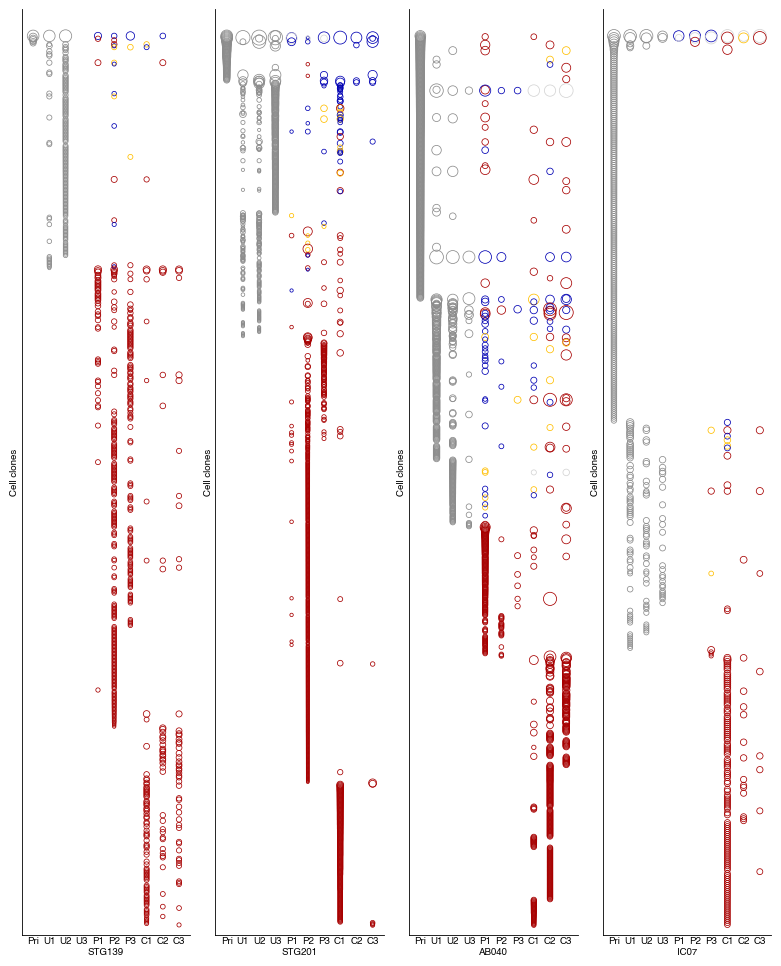

saved figEV1_legend_responses: 0.848 x 0.909 in


<Figure size 84.8x90.9 with 0 Axes>

saved figEV1_legend_clone_size: 0.835 x 1.137 in


<Figure size 83.5x113.7 with 0 Axes>

In [ ]:
# Bubble plots of clone size and response to treatment for every clone in every xenograft, one panel per model
sns.reset_defaults()
fs.apply_style()

bubble_model_order = ["STG139", "STG201", "AB040", "IC07"]
bubble_model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
bubble_colours = {"Diminished": "#0000b3", "Expanded": "#a70000", "Minimal change": "#FFBF00", "Inconsistent": "#d4d4d4", "N/A": "#8c8c8c"}
bubble_columns = ["Pri"] + [f"{letter}{i}" for letter in ["U", "P", "C"] for i in range(1, 4)]
cohort_of_letter = {"U": "Untreated", "P": "Paclitaxel", "C": "Carboplatin"}
BUBBLE_SCALE = 1.7        

def bubble_diameter_area(clone_size):
    return (BUBBLE_SCALE * np.log10(clone_size)) ** 2

def bubble_table(model):
    rows = []
    for item in full_stats[model]:
        row_cohort = item["secondary cohort info"]
        row = {"Barcode": item["barcode info"]["barcode"], "Pri size": item["barcode info"]["primary_cells"], "Pri response": "N/A"}
        for letter, cohort in cohort_of_letter.items():
            calls = row_cohort[cohort]["all_treated_responses"]
            inconsistent = cohort != "Untreated" and "Expanded" in calls and "Diminished" in calls
            for i in range(0, 3):
                column = f"{letter}{row_cohort[cohort]['mouse'][i]}"
                size = row_cohort[cohort]["all_num_cells"][i]
                if model == "STG139" and column == "U3":
                    size = 0
                row[f"{column} size"] = size
                row[f"{column} response"] = "N/A" if cohort == "Untreated" else ("Inconsistent" if inconsistent else calls[i])
        rows.append(row)
    table = pd.DataFrame(rows)
    size_columns = [f"{column} size" for column in bubble_columns]
    table = table.loc[table[size_columns].gt(0).any(axis=1)].copy()
    for letter in cohort_of_letter:
        mice = [f"{letter}{i} size" for i in range(1, 4) if not (model == "STG139" and letter == "U" and i == 3)]
        table[f"{letter} mean"] = table[mice].mean(axis=1)
    table = table.sort_values(["Pri size", "U mean", "P mean", "C mean"], ascending=False).reset_index(drop=True)
    return table

FIG_W, FIG_H = 7.714, 9.583
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, bottom, gap = 0.2, 0.02, 0.05, 0.28, 0.25
panel_w = (FIG_W - left - right - 3 * gap) / 4
axes = fs.inch_grid(fig, left, top, 1, 4, panel_w, FIG_H - top - bottom, gap, 0)[0]
for ax, model in zip(axes, bubble_model_order):
    table = bubble_table(model)
    for x, column in enumerate(bubble_columns):
        present = table.loc[table[f"{column} size"] > 0]
        colours = [bubble_colours.get(response, bubble_colours["N/A"]) for response in present[f"{column} response"]]
        ax.scatter(np.full(len(present), x), present.index, s=bubble_diameter_area(present[f"{column} size"]),
                   facecolors="none", edgecolors=colours, linewidths=0.55)
    ax.set_xlim(-0.7, len(bubble_columns) - 0.3)
    ax.set_ylim(len(table) - 0.5 + len(table) * 0.01, -len(table) * 0.03)     # first clone at the top
    ax.set_xticks(range(len(bubble_columns)))
    ax.set_xticklabels(bubble_columns)
    ax.set_yticks([])
    ax.set_xlabel(model, labelpad=1)
    ax.set_ylabel("Cell clones", labelpad=2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", length=0)
fs.save_panel(fig, "figEV1_amplicon_bubbleplot_clone_size_response")
plt.show()

response_handles = [mpl.lines.Line2D([], [], marker="s", linestyle="none", markersize=5, markerfacecolor=colour,
                                     markeredgecolor=colour, label=response) for response, colour in bubble_colours.items()]
size_handles = [mpl.lines.Line2D([], [], marker="o", linestyle="none", markerfacecolor="none", markeredgecolor="#333333",
                                 markeredgewidth=0.55, markersize=BUBBLE_SCALE * exponent, label=str(exponent))
                for exponent in range(2, 7)]
fs.legend_panel("figEV1_legend_responses", 0.848, 0.909, response_handles, loc="upper left", handlelength=0.8,
                handletextpad=0.3, labelspacing=0.3, pad_top=0.08)       # clear of the bubble plots' bottom edge
plt.show()
fs.legend_panel("figEV1_legend_clone_size", 0.835, 1.137, size_handles, loc="upper left", title="Clone size (10$^{x}$)", pad_top=0.08,
                handlelength=1.2, handletextpad=0.7, labelspacing=0.75)
plt.show()

saved figS3B_amplicon_boxplot_clone_size_per_mouse: 4.110 x 3.323 in


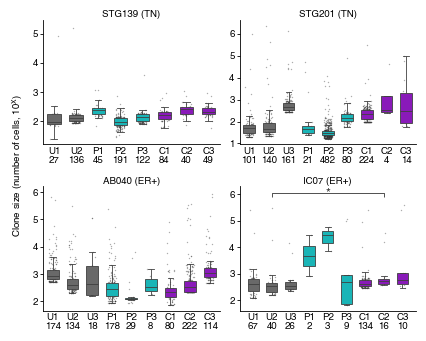

,Tumor,Comparison,Mice,Median clone size (first cohort),Median clone size (second cohort),Fold difference (mouse level),95% CI low,95% CI high,p (mouse-level Student's t),"p (clone-level Mann-Whitney, descriptive)"
0,STG139,Paclitaxel vs Untreated,3 vs 2,124.135,131.59,1.301158,0.376756,4.493651,0.547510,1.150097e-01
1,STG139,Carboplatin vs Untreated,3 vs 2,193.420,131.59,1.892324,0.936243,3.824745,0.063296,3.155374e-19
2,STG201,Paclitaxel vs Untreated,3 vs 3,30.690,104.93,0.582750,0.049428,6.870479,0.576213,2.404046e-47
3,STG201,Carboplatin vs Untreated,3 vs 3,210.370,104.93,2.837082,0.352435,22.838352,0.237404,2.309465e-05
4,AB040,Paclitaxel vs Untreated,3 vs 3,264.540,694.48,0.427964,0.148708,1.231628,0.089688,2.439260e-30
5,AB040,Carboplatin vs Untreated,3 vs 3,409.000,694.48,0.810516,0.181375,3.621984,0.716680,9.626108e-09
6,IC07,Paclitaxel vs Untreated,3 vs 3,850.535,361.36,11.231790,0.427758,294.917346,0.109074,6.320401e-02
7,IC07,Carboplatin vs Untreated,3 vs 3,438.385,361.36,1.418436,1.012997,1.986146,0.044880,9.804920e-05


In [ ]:
# Box and whisker plot of clone sizes in each individual mouse, grouped by cohort, with cohort medians compared
sns.reset_defaults()
fs.apply_style()

cohort_order = ["Untreated", "Paclitaxel", "Carboplatin"]
cohort_colours = {"Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
model_order = ["STG139", "STG201", "AB040", "IC07"]
SIG_ALPHA = fs.SIG_ALPHA
BRACKET_DECADES = 0.45  
comparisons = [("Untreated", "Paclitaxel"), ("Untreated", "Carboplatin")]   

def log_tick_formatter(val, pos):
    return f'{int(np.log10(val))}'

def p_stars(p):
    return fs.stars(p) or "ns"

def mouse_level_median_test(log_a, log_b):
    log_a, log_b = np.asarray(log_a), np.asarray(log_b)
    n_a, n_b = len(log_a), len(log_b)
    diff = log_b.mean() - log_a.mean()
    dof = n_a + n_b - 2
    pooled_sd = np.sqrt(((n_a - 1) * log_a.var(ddof=1) + (n_b - 1) * log_b.var(ddof=1)) / dof)
    half_width = scipy.stats.t.ppf(0.975, dof) * pooled_sd * np.sqrt(1 / n_a + 1 / n_b)
    p = scipy.stats.ttest_ind(log_b, log_a).pvalue
    return 10 ** diff, 10 ** (diff - half_width), 10 ** (diff + half_width), p

FIG_W, FIG_H = 4.110, 3.323
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, wgap, hgap, bottom = 0.36, 0.02, 0.15, 0.2, 0.42, 0.26
panel_w = (FIG_W - left - right - wgap) / 2
panel_h = (FIG_H - top - hgap - bottom) / 2
axes = fs.inch_grid(fig, left, top, 2, 2, panel_w, panel_h, wgap, hgap)
median_test_rows = []
for ax, model in zip(axes.flatten(), model_order):
    df = pd.DataFrame(clonal_comp_for_bargraph_treated_response[model])
    if model == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    df["Sample"] = df["Cohort"] + " " + df["Mouse"].astype(str)
    sample_order = [f"{cohort} {mouse}" for cohort in cohort_order for mouse in sorted(df.loc[df["Cohort"] == cohort, "Mouse"].unique())]
    df["Log10 clone size"] = np.log10(df["Cell counts"])
    mouse_medians = df.groupby(["Cohort", "Mouse"])["Log10 clone size"].median()

    sns.boxplot(ax=ax, data=df, x="Sample", y="Cell counts", order=sample_order, hue="Cohort", hue_order=cohort_order,
                palette=cohort_colours, dodge=False, width=0.6, showfliers=False, linewidth=0.6, log_scale=True)
    sns.stripplot(ax=ax, data=df, x="Sample", y="Cell counts", order=sample_order, color="#333333", size=1, alpha=0.4,
                  jitter=0.2, zorder=0.5)

    y_max = df["Cell counts"].max()
    n_bars = 0
    for a, b in comparisons:
        pos_a = [i for i, s in enumerate(sample_order) if s.startswith(a)]
        pos_b = [i for i, s in enumerate(sample_order) if s.startswith(b)]
        log_a, log_b = mouse_medians.loc[a], mouse_medians.loc[b]
        fold, ci_low, ci_high, p = mouse_level_median_test(log_a, log_b)
        clone_p = scipy.stats.mannwhitneyu(df.loc[df["Cohort"] == b, "Cell counts"], df.loc[df["Cohort"] == a, "Cell counts"]).pvalue
        median_test_rows.append({
            "Tumor": model, "Comparison": f"{b} vs {a}", "Mice": f"{len(log_b)} vs {len(log_a)}",
            f"Median clone size (first cohort)": df.loc[df["Cohort"] == b, "Cell counts"].median(),
            f"Median clone size (second cohort)": df.loc[df["Cohort"] == a, "Cell counts"].median(),
            "Fold difference (mouse level)": fold, "95% CI low": ci_low, "95% CI high": ci_high,
            "p (mouse-level Student's t)": p, "p (clone-level Mann-Whitney, descriptive)": clone_p
        })
        if p >= SIG_ALPHA:
            continue
        n_bars += 1
        bar_y = y_max * 10 ** (BRACKET_DECADES * n_bars)
        fs.log_significance_bracket(ax, np.mean(pos_a), np.mean(pos_b), bar_y, p)
    ax.set_ylim(top=y_max * 10 ** (BRACKET_DECADES * (n_bars + 0.6)))

    n_clones = df.groupby("Sample").size()
    ax.set_xticks(range(len(sample_order)))
    ax.set_xticklabels([f"{s.split(' ')[0][0]}{s.split(' ')[1]}\n{n_clones[s]}" for s in sample_order], linespacing=1.0)
    ax.tick_params(axis="x", length=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))
    ax.yaxis.set_minor_locator(mticker.NullLocator())
    ax.set_title(f"{model} ({model_type[model]})")
    ax.set(xlabel=None, ylabel=None)
    ax.legend_.remove()
    ax.spines[["top", "right"]].set_visible(False)

fs.fig_text(fig, 0.03, top + panel_h + hgap / 2, "Clone size (number of cells, 10$^{X}$)", rotation="vertical",
            ha="left", va="center")
fs.save_panel(fig, "figS3B_amplicon_boxplot_clone_size_per_mouse")
plt.show()

median_tests = pd.DataFrame(median_test_rows)
median_tests.to_csv("../data_files/amplicon_data/amplicon_clone_size_per_mouse_median_tests.csv", index=False)
median_tests

saved figS3A_amplicon_clone_number: 3.459 x 3.459 in


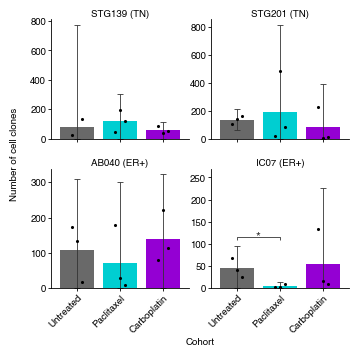

 Tumor               Comparison  p (Student's t)
STG139  Paclitaxel vs Untreated           0.6164
STG139 Carboplatin vs Untreated           0.6269
STG201  Paclitaxel vs Untreated           0.7004
STG201 Carboplatin vs Untreated           0.5101
 AB040  Paclitaxel vs Untreated           0.6302
 AB040 Carboplatin vs Untreated           0.6608
  IC07  Paclitaxel vs Untreated           0.0316
  IC07 Carboplatin vs Untreated           0.8413


In [ ]:
# Bar graph of the number of clones per mouse by cohort

sns.reset_defaults()
fs.apply_style()

order = ["Untreated", "Paclitaxel", "Carboplatin"]
cohort_colours = {"Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
model_order = ["STG139", "STG201", "AB040", "IC07"]

def t_confidence_interval(values):
    values = np.asarray(values, dtype=float)
    half_width = scipy.stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return max(values.mean() - half_width, 0), values.mean() + half_width

FIG_W, FIG_H = 3.459, 3.459
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, wgap, hgap, bottom = 0.45, 0.03, 0.15, 0.22, 0.3, 0.62
panel_w = (FIG_W - left - right - wgap) / 2
panel_h = (FIG_H - top - hgap - bottom) / 2
axes = fs.inch_grid(fig, left, top, 2, 2, panel_w, panel_h, wgap, hgap)
clone_number_tests = []
for i, ax in enumerate(axes.flatten()):
    model = model_order[i]
    df = pd.DataFrame(clonal_comp_for_bargraph_treated_response[model])
    if model == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    grouped = df.groupby(["Cohort", "Mouse"]).size().rename("Num clones").reset_index()

    tops = []
    for j, cohort in enumerate(order):
        values = grouped.loc[grouped["Cohort"] == cohort, "Num clones"].values
        low, high = t_confidence_interval(values)
        ax.bar(j, values.mean(), width=0.8, color=cohort_colours[cohort], linewidth=0)
        ax.errorbar(j, values.mean(), yerr=[[values.mean() - low], [high - values.mean()]], color="#333333",
                    capsize=2, linewidth=0.6, capthick=0.6)
        jitter = np.linspace(-0.12, 0.12, len(values)) if len(values) > 1 else np.zeros(1)
        ax.scatter(j + jitter, values, s=5, color="black", linewidths=0, zorder=3)
        tops.append(max(high, values.max()))
    data_top = max(tops)

    level = 0
    untreated = grouped.loc[grouped["Cohort"] == "Untreated", "Num clones"].values
    for j, cohort in enumerate(order[1:], start=1):
        treated = grouped.loc[grouped["Cohort"] == cohort, "Num clones"].values
        p = scipy.stats.ttest_ind(untreated, treated).pvalue
        clone_number_tests.append({"Tumor": model, "Comparison": f"{cohort} vs Untreated", "p (Student's t)": p})
        if fs.stars(p):
            y = max(tops[0], tops[j]) + data_top * (0.08 + 0.14 * level)
            fs.significance_bracket(ax, 0, j, y, p, tick=data_top * 0.03)
            level += 1
    ax.set_ylim(0, data_top * (1.05 + 0.14 * level))
    ax.set_title(f"{model} ({model_type[model]})")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order if i >= 2 else [], rotation=45, ha="right", rotation_mode="anchor")
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.spines[["top", "right"]].set_visible(False)
fs.fig_text(fig, left + panel_w + wgap / 2, FIG_H - 0.04, "Cohort", ha="center", va="bottom")
fs.fig_text(fig, 0.04, top + panel_h + hgap / 2, "Number of cell clones", rotation="vertical", ha="left", va="center")
fs.save_panel(fig, "figS3A_amplicon_clone_number")
plt.show()
print(pd.DataFrame(clone_number_tests).round(4).to_string(index=False))

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/3444270595.py:151: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=table.replace(amp_to_int).astype(float), cmap=ListedColormap(response_colours),
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/3444270595.py:151: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=table.replace(amp_to_int).astype(float), cmap=ListedColormap(response_colours),
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/3444270595.py:151

saved fig2B_amplicon_heatmap_clonal_response_to_treatment: 3.768 x 4.721 in


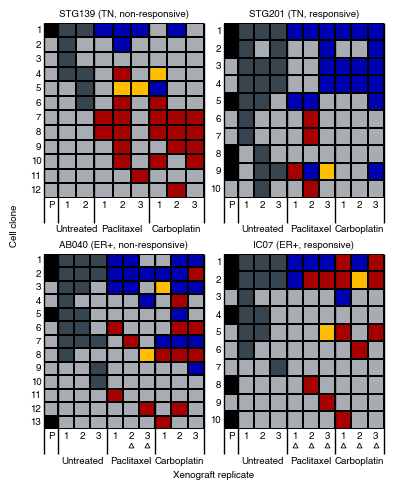

saved fig2B_legend_responses: 0.449 x 2.901 in


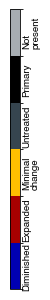

In [ ]:
# Graph heatmaps of top 5 most prevalent clones in each tumor by the percent they make up of the tumor
## NOTE: If any of the top 3 are in another column, there will be fewer rows in the final heatmap
num_top_clones = 3
dict_of_dfs_heatmap = {}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

import figure_style as fs
plt.rcdefaults()
fs.apply_style()

for key, val in clonal_comp_for_bargraph_treated_response.items():
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    
    top_barcodes = []
    for cohort in df["Cohort"].unique():
        for mouse in range(1, 4):
            curr_df = df.copy()
            curr_df = curr_df.loc[(curr_df["Cohort"] == cohort) & (curr_df["Mouse"] == mouse)].sort_values("Cell counts", ascending=False).reset_index(drop=True)
            top_clones = curr_df.head(num_top_clones)
            barcodes = top_clones["Barcode"].to_list()
            top_barcodes.extend(barcodes)
    
    top_barcodes = list(set(top_barcodes))
    top_clones_df = df.loc[df["Barcode"].isin(top_barcodes)]
    top_clones_df = top_clones_df.sort_values(["Cohort", "Mouse", "Cell counts"], ascending=[False, True, False]).reset_index(drop=True)
    
    final_df = top_clones_df.sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    final_df["Cohort mouse"] = final_df["Cohort"] + " " + final_df["Mouse"].astype("str")

    dict_of_dfs_heatmap[key] = final_df

key_order = ["STG139", "STG201", "AB040", "IC07"]
sorted_dict = {}
for key in key_order:
    if key in dict_of_dfs_heatmap:  
        sorted_dict[key] = dict_of_dfs_heatmap[key]

HEATMAP_COLUMNS = {key: (['Untreated 1', 'Untreated 2'] if key == "STG139" else ['Untreated 1', 'Untreated 2', 'Untreated 3'])
                   + ['Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']
                   for key in key_order}
model_responsiveness = {"STG139": "non-responsive", "AB040": "non-responsive", "STG201": "responsive", "IC07": "responsive"}

late_growth = pd.read_csv("../data_files/tumor_volume/tumor_growth_late_growing_treated.csv")
mouse_number = full_data.drop_duplicates(subset=["Mouse"]).set_index("Mouse")["Mouse num"]
late_columns = {(r.model, f"{r.cohort} {int(mouse_number[r.mouse])}") for r in late_growth.itertuples()}
mouse_ids = full_data.drop_duplicates(subset=["Tumor", "Cohort", "Mouse num"]).set_index(["Tumor", "Cohort", "Mouse num"])["Mouse"]
primary_mouse = {}
for key in key_order:
    found = full_data.loc[(full_data["Tumor"] == key) & (full_data["Cohort"] == "Primary"), "Mouse"].unique()
    assert len(found) == 1, (key, found)
    primary_mouse[key] = found[0]
primary_percent = {key: {d["Barcode"]: d["Percent"] for d in clonal_comp_for_bargraph_treated_response_primary[key]
                         if d["Cohort"] == "Primary"} for key in key_order}
for key, percents in primary_percent.items():
    assert abs(sum(percents.values()) - 100) < 1e-3, (key, sum(percents.values()))     # 100, to rounding
PRIMARY_W = 0.14                                               # in: the Primary column of each heatmap

def top_clone_heatmaps(width, height, draw_map, row_label_width=0.24):
    """The 2 x 2 layout of Figures 2A and 2B at their size on the page. draw_map(ax_p, ax, key) draws one model's
    heatmap: the primary tumour's column in ax_p and the secondaries (columns in HEATMAP_COLUMNS[key] order) in ax; the
    row labels go on ax_p. Under each heatmap: "P" and the replicate numbers, a triangle under each late-regrowth
    xenograft, then the cohort names, with black lines either side of the Primary column and between cohorts running
    from the heatmap's top down to them"""
    fig = fs.new_panel(width, height)
    left, right, title_h, under_h, bottom_h, row_gap = 0.15 + row_label_width, 0.02, 0.14, 0.38, 0.14, 0.04
    map_w = (width - left - row_label_width - right) / 2          # the Primary column and the secondaries
    map_h = (height - 2 * title_h - 2 * under_h - row_gap - bottom_h) / 2
    for k, key in enumerate(key_order):
        r, c = divmod(k, 2)
        map_left = left + c * (map_w + row_label_width)
        map_top = title_h + r * (map_h + under_h + row_gap + title_h)
        ax_p = fs.inch_axes(fig, map_left, map_top, PRIMARY_W, map_h)
        ax = fs.inch_axes(fig, map_left + PRIMARY_W, map_top, map_w - PRIMARY_W, map_h)
        draw_map(ax_p, ax, key)
        columns = HEATMAP_COLUMNS[key]
        for a in (ax_p, ax):
            a.set(xlabel=None, ylabel=None)
            a.tick_params(axis="x", length=0, pad=2)
        fs.fig_text(fig, map_left + map_w / 2, map_top - 3 / 72, f"{key} ({model_type[key]}, {model_responsiveness[key]})",
                    ha="center", va="bottom")             # over the Primary column and the secondaries
        ax_p.set_xticks([0.5])
        ax_p.set_xticklabels(["P"], rotation=0)
        ax_p.tick_params(axis="y", length=0, pad=2, rotation=0)
        ax.set_yticks([])
        ax.set_xticks([i + 0.5 for i in range(len(columns))])
        ax.set_xticklabels([col.split(" ")[1] for col in columns], rotation=0)
        below_p = mpl.transforms.blended_transform_factory(ax_p.transData, ax_p.transAxes)
        ax_p.plot([0, 0], [1, -0.25 / map_h], color="black", linewidth=1.0, transform=below_p, clip_on=False, zorder=5,
                  solid_capstyle="butt")                  # the Primary column's left; Untreated's left line is its right
        below = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        depth = under_h / map_h                                    # the space under the heatmap, in axes units
        cohorts = [col.split(" ")[0] for col in columns]
        bounds = [0] + [i for i in range(1, len(columns)) if cohorts[i] != cohorts[i - 1]] + [len(columns)]
        for x in bounds:                                           # down to the cohort names, not through them
            ax.plot([x, x], [1, -0.25 / map_h], color="black", linewidth=1.0, transform=below, clip_on=False, zorder=5,
                    solid_capstyle="butt")
        for a, b in zip(bounds[:-1], bounds[1:]):
            ax.text((a + b) / 2, -depth + 0.01, cohorts[a], transform=below, ha="center", va="bottom")
        for i, col in enumerate(columns):
            if (key, col) in late_columns:
                ax.plot(i + 0.5, -0.155 / map_h, marker="^", markersize=3.5, markerfacecolor="white",
                        markeredgecolor="black", markeredgewidth=0.6, transform=below, clip_on=False)
    fs.fig_text(fig, left + map_w + row_label_width / 2, height - 0.01, "Xenograft replicate", ha="center", va="bottom")
    fs.fig_text(fig, 0.01, title_h + map_h + (under_h + row_gap + title_h) / 2, "Cell clone", rotation=90, ha="left",
                va="center")
    return fig

def heatmap_source_data(tables, primary, barcodes, value_name):
    rows = []
    for key, table in tables.items():
        for heatmap_row, barcode in zip(table.index, barcodes[key]):
            clone = {"Model": key, "Subtype": model_type[key],
                     "Model responsiveness": model_responsiveness[key].capitalize(),
                     "Heatmap row": heatmap_row, "Barcode": barcode}
            rows.append({**clone, "Cohort": "Primary", "Replicate": pd.NA, "Mouse ID": primary_mouse[key],
                         "Late regrowth (open triangle)": False, value_name: primary[key].loc[heatmap_row, "Primary"]})
            for col in table.columns:
                cohort, replicate = col.split(" ")
                rows.append({**clone, "Cohort": cohort, "Replicate": int(replicate),
                             "Mouse ID": mouse_ids[(key, cohort, int(replicate))],
                             "Late regrowth (open triangle)": (key, col) in late_columns,
                             value_name: table.loc[heatmap_row, col]})
    data = pd.DataFrame(rows)
    data["Replicate"] = data["Replicate"].astype("Int64")         # empty for the primary
    return data

response_colours = ["#0000b3", "#a70000", "#FFBF00", "#36454F", "#000000", "#a7adb2"]   # ..., Primary (black), Not present

def draw_response_map(ax_p, ax, key):
    for a, table in ((ax_p, response_primary[key]), (ax, response_tables[key])):
        sns.heatmap(data=table.replace(amp_to_int).astype(float), cmap=ListedColormap(response_colours),
                    vmin=-0.5, vmax=len(response_colours) - 0.5, ax=a, cbar=False, linewidths=0.2, linecolor="black")

amp_to_int = {'Diminished': 0, 'Expanded': 1, 'Minimal change': 2, "Untreated": 3, "Primary": 4, "Not Present": 5}
response_tables = {}
response_barcodes = {}
response_primary = {}                                         # black where the primary had the clone
for key, val in sorted_dict.items():
    # Grab the data & organize
    pivot_df = val[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = pivot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)
    pivot_responses = val[["Cohort mouse", "Barcode", "Response"]]
    pivot_responses = pivot_responses.pivot(index='Barcode', columns='Cohort mouse', values='Response').fillna("Not Present")
    columns = HEATMAP_COLUMNS[key]
    pivot_df = pivot_df[columns].sort_values(columns, ascending=False)
    response_barcodes[key] = list(pivot_df.index)
    ordered_responses = pivot_responses.loc[pivot_df.index, columns].reset_index(drop=True)
    ordered_responses.index = ordered_responses.index + 1
    response_tables[key] = ordered_responses
    response_primary[key] = pd.DataFrame({"Primary": ["Primary" if bc in primary_percent[key] else "Not Present"
                                                      for bc in response_barcodes[key]]}, index=ordered_responses.index)

fig = top_clone_heatmaps(3.488 + 2 * PRIMARY_W, 4.721, draw_response_map, row_label_width=0.2)
fs.save_panel(fig, "fig2B_amplicon_heatmap_clonal_response_to_treatment")
plt.show()
heatmap_source_data(response_tables, response_primary, response_barcodes, "Response").to_csv(
    "../data_files/amplicon_data/fig2B_amplicon_heatmap_clonal_response_to_treatment.csv", index=False)

key_labels = ["Diminished", "Expanded", "Minimal\nchange", "Untreated", "Primary", "Not\npresent"]
key_height = 0.1 + len(key_labels) * (2.434 - 0.1) / 5            # each entry as tall as before Primary was added
fig = fs.new_panel(0.449, key_height)
cax = fs.inch_axes(fig, 0.05, 0.05, 0.1, key_height - 0.1)
colorbar = fig.colorbar(mpl.cm.ScalarMappable(norm=mcolors.BoundaryNorm(np.arange(-0.5, len(key_labels)), len(key_labels)),
                                              cmap=ListedColormap(response_colours)), cax=cax)
colorbar.set_ticks(range(len(key_labels)))
colorbar.set_ticklabels(key_labels, rotation=90, va="center", linespacing=1.0)
colorbar.ax.tick_params(length=0)
colorbar.outline.set_linewidth(fs.LINE)
fs.save_panel(fig, "fig2B_legend_responses", transparent=True)
plt.show()

saved fig2A_amplicon_heatmap_clonal_composition: 3.877 x 4.721 in


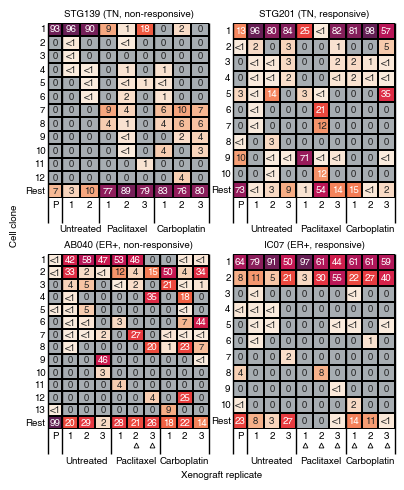

saved fig2A_legend_percent: 0.583 x 1.721 in


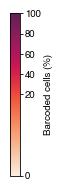

In [ ]:
# Graph heatmaps of top X most prevalent clones in each tumor by the percent they make up of the tumor
## NOTE: If any of the top X are in another column, there will be fewer rows in the final heatmap
plt.rcdefaults()
fs.apply_style()

num_top_clones = 3
dict_of_dfs_heatmap = {}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

for key, val in clonal_comp_for_bargraph_treated_response.items():
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    
    top_barcodes = []
    for cohort in df["Cohort"].unique():
        for mouse in range(1, 4):
            curr_df = df.copy()
            curr_df = curr_df.loc[(curr_df["Cohort"] == cohort) & (curr_df["Mouse"] == mouse)].sort_values("Cell counts", ascending=False).reset_index(drop=True)
            top_clones = curr_df.head(num_top_clones)
            barcodes = top_clones["Barcode"].to_list()
            top_barcodes.extend(barcodes)
    
    top_barcodes = list(set(top_barcodes))
    top_clones_df = df.loc[df["Barcode"].isin(top_barcodes)]
    top_clones_df = top_clones_df.sort_values(["Cohort", "Mouse", "Cell counts"], ascending=[False, True, False]).reset_index(drop=True)
    
    remaining_df = df.loc[~df["Barcode"].isin(top_barcodes)]
    remaining_df = remaining_df.groupby(["Cohort", "Mouse"]).sum().reset_index()
    remaining_df["Response"] = "Resistant"
    remaining_df["Barcode"] = "All remaining"

    final_df = pd.concat([top_clones_df, remaining_df]).sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    final_df["Cohort mouse"] = final_df["Cohort"] + " " + final_df["Mouse"].astype("str")

    dict_of_dfs_heatmap[key] = final_df

key_order = ["STG139", "STG201", "AB040", "IC07"]
sorted_dict = {}
for key in key_order:
    if key in dict_of_dfs_heatmap:  
        sorted_dict[key] = dict_of_dfs_heatmap[key]

rocket_r_adjust = ListedColormap(mpl.colormaps["rocket_r"](np.linspace(0, 0.75, 256)))
rocket_r_adjust.set_under(color="#a7adb2")
vmin, vmax = 0.000000001, 100
vcenter = 20
normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)

def percent_label(value):
    return "0" if value == 0 else ("<1" if value < 1 else f"{value:.0f}")

composition_tables = {}
composition_barcodes = {}
composition_primary = {}
for key, val in sorted_dict.items():
    plot_df = val[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = plot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)
    columns = HEATMAP_COLUMNS[key]
    pivot_df = pivot_df[columns].sort_values(columns, ascending=False)
    all_remaining = pivot_df.loc["All remaining"]
    pivot_df = pivot_df.drop(["All remaining"], axis=0)
    composition_barcodes[key] = list(pivot_df.index) + ["All remaining"]
    pivot_df = pivot_df.reset_index(drop=True)
    pivot_df.index = pivot_df.index + 1
    pivot_df.loc["Rest"] = all_remaining
    composition_tables[key] = pivot_df
    shown = composition_barcodes[key][:-1]
    percents = primary_percent[key]
    composition_primary[key] = pd.DataFrame(            
        {"Primary": [percents.get(bc, 0.0) for bc in shown] + [sum(p for bc, p in percents.items() if bc not in shown)]},
        index=pivot_df.index)

def draw_composition_map(ax_p, ax, key):
    for a, table in ((ax_p, composition_primary[key]), (ax, composition_tables[key])):
        sns.heatmap(data=table, cmap=rocket_r_adjust, norm=normalize, vmin=vmin, vmax=vmax, ax=a, cbar=False,
                    linewidths=0.2, linecolor="black", annot=table.map(percent_label).values, fmt="",
                    annot_kws={"size": fs.FONT})

fig = top_clone_heatmaps(3.597 + 2 * PRIMARY_W, 4.721, draw_composition_map, row_label_width=0.24)
fs.save_panel(fig, "fig2A_amplicon_heatmap_clonal_composition")
plt.show()
fig2A_data = heatmap_source_data(composition_tables, composition_primary, composition_barcodes, "Barcoded cells (%)")
fig2A_data["Value shown"] = fig2A_data["Barcoded cells (%)"].map(percent_label)
fig2A_data.to_csv("../data_files/amplicon_data/fig2A_amplicon_heatmap_clonal_composition.csv", index=False)

fig = fs.new_panel(0.583, 1.721)
cax = fs.inch_axes(fig, 0.05, 0.05, 0.1, 1.721 - 0.1)
colorbar = fig.colorbar(mpl.cm.ScalarMappable(norm=mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=0, vmax=vmax),
                                              cmap=rocket_r_adjust), cax=cax)
colorbar.set_ticks([0, 20, 40, 60, 80, 100])
colorbar.set_label("Barcoded cells (%)", labelpad=2)
colorbar.outline.set_linewidth(fs.LINE)
fs.save_panel(fig, "fig2A_legend_percent", transparent=True)
plt.show()

In [ ]:
# Set up table to summarize unique clones in each cohort - binary, broken down more: number of each clone type that's sensitive/ resistant
models = full_data["Tumor"].unique()
secondary_cohorts = ["Untreated", "Carboplatin", "Paclitaxel"]
unique_bc_seqs = full_data.drop_duplicates(subset=["Tumor", "Cohort", "Mouse", "var_seq"])

summary_data = {}

# Summarize transient, propagating, and emerging clones and their response to treatment
for tumor in models:
    if tumor != "STG139":
        summary_info = {"common": {
                            "primary clones": 0,
                            "transient": 0
                        },
                        "secondaries": { 
                            "Untreated": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                            },
                            "Carboplatin": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                            },
                            "Paclitaxel": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                }
                        }}}
    else:
        summary_info = {"common": {
                        "primary clones": 0,
                        "transient": 0
                    },
                    "secondaries": { 
                        "Untreated": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            }
                        },
                        "Paclitaxel": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 3": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                        },
                        "Carboplatin": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 3": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            }
                    }}}
    for bc_dict in full_stats[tumor]:
        cohort_info = bc_dict["secondary cohort info"]
        bc_info = bc_dict["barcode info"]
        if bc_info["secondary_presence"] > 0:
            if bc_info["primary_cells"] > 0:
                prop_emerg = "propagating"
                summary_info["common"]["primary clones"] += 1
            else:
                prop_emerg = "emerging"
            for cohort in cohort_info.keys():
                if cohort_info[cohort]["presence"] > 0:
                    summary_info["secondaries"][cohort]["Unique clones"] += 1
                    for i, response in enumerate(cohort_info[cohort]["all_treated_responses"]):
                        if response != "Not present":
                            if cohort != "Untreated":
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"][f"{prop_emerg} {response}"] += 1
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"]["total"] += 1
                            else:
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"][f"{prop_emerg} Diminished"] += 1
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"]["total"] += 1
        elif bc_info["secondary_presence"] == 0 and bc_info["primary_cells"] > 0:
            summary_info["common"]["primary clones"] += 1
            summary_info["common"]["transient"] += 1    

    for cohort in summary_info["secondaries"].keys():
        if tumor == "STG139" and cohort == "Untreated":
            summary_data[(tumor, cohort, "Replicate 1")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 1"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Diminished"], 
            summary_info["secondaries"][cohort]["Replicate 1"]["propagating Minimal change"],summary_info["secondaries"][cohort]["Replicate 1"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 2")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 2"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Expanded"]]

        else:
            summary_data[(tumor, cohort, "Replicate 1")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 1"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 2")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 2"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 3")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 3"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Expanded"]]

index = pd.MultiIndex.from_tuples([("", "", "Unique clones primary PDTX"), 
                                   ("", "", "Unique clones secondary PDTX"), 
                                   ("", "", "Unique clones per replicate"),
                                   ("Clone type & treatment response", "Transient", ""), 
                                   ("Clone type & treatment response", "Propagating", "Diminished"), ("Clone type & treatment response", "Propagating", "Minimal change"), 
                                   ("Clone type & treatment response", "Propagating", "Expanded"), 
                                   ("Clone type & treatment response", "Emerging", "Diminished"), ("Clone type & treatment response", "Emerging", "Minimal change"), 
                                   ("Clone type & treatment response", "Emerging", "Expanded")])
summary_df_v6 = pd.DataFrame(summary_data, index=index).transpose()

In [ ]:
# Table: unique clones and clone type (transient, propagating, emerging) per mouse
clone_col = "Clone type & treatment response"
clone_type_df = summary_df_v6[[("", "", "Unique clones primary PDTX"), ("", "", "Unique clones secondary PDTX"), ("", "", "Unique clones per replicate")]].droplevel([0, 1], axis=1)
clone_type_df["Transient"] = summary_df_v6[(clone_col, "Transient", "")]
for clone_type in ["Propagating", "Emerging"]:
    clone_type_df[clone_type] = summary_df_v6.xs((clone_col, clone_type), axis=1, level=[0, 1]).sum(axis=1)
clone_type_df.index.names = ["Tumor", "Cohort", "Mouse"]

# Propagating + emerging accounts for every clone in the mouse
assert (clone_type_df["Propagating"] + clone_type_df["Emerging"] == clone_type_df["Unique clones per replicate"]).all()

In [ ]:
# Table: number of clones diminished, minimal change, and expanded per treated mouse
clone_col = "Clone type & treatment response"
response_df = pd.DataFrame(index=summary_df_v6.index)
for response in ["Diminished", "Minimal change", "Expanded"]:
    response_df[response] = summary_df_v6[(clone_col, "Propagating", response)] + summary_df_v6[(clone_col, "Emerging", response)]
response_df.index.names = ["Tumor", "Cohort", "Mouse"]
response_df = response_df.drop(index="Untreated", level="Cohort")

# The three responses account for every clone in the treated mouse
assert (response_df.sum(axis=1) == summary_df_v6[("", "", "Unique clones per replicate")].drop(index="Untreated", level=1)).all()

In [ ]:
# Percent of each mouse's clones by clone type and by treatment response, and untreated vs treated tests
SIG_ALPHA = 0.05
treated_cohorts = ["Paclitaxel", "Carboplatin"]
response_types = ["Expanded", "Diminished", "Minimal change", "Discrepant"]
tested_response_types = [r for r in response_types if r != "Discrepant"]   

def compare_percentages(untreated_pcts, treated_pcts):
    u, t = np.asarray(untreated_pcts, dtype=float), np.asarray(treated_pcts, dtype=float)
    diff = t.mean() - u.mean()
    dof = len(u) + len(t) - 2
    pooled_sd = np.sqrt(((len(u) - 1) * u.var(ddof=1) + (len(t) - 1) * t.var(ddof=1)) / dof)
    if pooled_sd == 0:
        return diff, np.nan, np.nan, np.nan   
    half_width = scipy.stats.t.ppf(0.975, dof) * pooled_sd * np.sqrt(1 / len(u) + 1 / len(t))
    return diff, diff - half_width, diff + half_width, scipy.stats.ttest_ind(t, u).pvalue

def test_row(model, measure, cohort, untreated_pcts, treated_pcts, unit="%"):
    diff, ci_low, ci_high, p = compare_percentages(untreated_pcts, treated_pcts)
    mean_label, diff_label = ("%", "% points") if unit == "%" else (f"({unit})", unit)
    return {"Tumor": model, "Measure": measure, "Comparison": f"{cohort} vs Untreated",
            "Mice (untreated, treated)": f"{len(untreated_pcts)}, {len(treated_pcts)}",
            f"Untreated mean {mean_label}": np.mean(untreated_pcts), f"Treated mean {mean_label}": np.mean(treated_pcts),
            f"Difference (treated - untreated, {diff_label})": diff, "95% CI low": ci_low, "95% CI high": ci_high,
            "p (Student's t, mice as replicates)": p, "Significant": bool(p < SIG_ALPHA) if not np.isnan(p) else "not testable"}

clone_type_pct_df = clone_type_df[["Unique clones per replicate", "Propagating", "Emerging"]].copy()
for clone_type in ["Propagating", "Emerging"]:
    clone_type_pct_df[f"% {clone_type}"] = 100 * clone_type_pct_df[clone_type] / clone_type_pct_df["Unique clones per replicate"]

transient_pct_df = clone_type_df.groupby(level="Tumor")[["Unique clones primary PDTX", "Transient"]].first()
transient_pct_df["% Transient (of primary clones)"] = 100 * transient_pct_df["Transient"] / transient_pct_df["Unique clones primary PDTX"]

clone_type_tests = []
for model in clone_type_pct_df.index.get_level_values("Tumor").unique():
    model_df = clone_type_pct_df.loc[model]
    for cohort in treated_cohorts:
        for clone_type in ["Propagating", "Emerging"]:
            clone_type_tests.append(test_row(model, f"% {clone_type}", cohort,
                                             model_df.loc["Untreated", f"% {clone_type}"], model_df.loc[cohort, f"% {clone_type}"]))
clone_type_tests = pd.DataFrame(clone_type_tests)

clone_count_tests = []
for model in clone_type_pct_df.index.get_level_values("Tumor").unique():
    model_df = clone_type_pct_df.loc[model]
    for cohort in treated_cohorts:
        for clone_type in ["Propagating", "Emerging"]:
            clone_count_tests.append(test_row(model, f"Number of {clone_type.lower()} clones", cohort,
                                              model_df.loc["Untreated", clone_type], model_df.loc[cohort, clone_type], unit="clones"))
clone_count_tests = pd.DataFrame(clone_count_tests)

response_rows = []
for model, model_info in full_stats.items():
    for item in model_info:
        row_cohort = item["secondary cohort info"]
        for drug in treated_cohorts:
            for i in range(0, 3):
                if row_cohort[drug]["all_num_cells"][i] > 0:
                    response_rows.append({"Tumor": model, "Drug": drug, "Cohort": drug, "Mouse": f"Replicate {row_cohort[drug]['mouse'][i]}",
                                          "Response": row_cohort[drug]["all_treated_responses"][i]})
                if row_cohort["Untreated"]["all_num_cells"][i] > 0:
                    response_rows.append({"Tumor": model, "Drug": drug, "Cohort": "Untreated", "Mouse": f"Replicate {row_cohort['Untreated']['mouse'][i]}",
                                          "Response": row_cohort["Untreated"][f"all_untreated_{drug}_responses"][i]})
response_long = pd.DataFrame(response_rows)
response_long = response_long.drop(response_long[(response_long["Tumor"] == "STG139") & (response_long["Cohort"] == "Untreated") & (response_long["Mouse"] == "Replicate 3")].index)
assert set(response_long["Response"]) <= set(response_types), set(response_long["Response"]) - set(response_types)

response_pct_df = pd.crosstab([response_long["Tumor"], response_long["Drug"], response_long["Cohort"], response_long["Mouse"]], response_long["Response"])
response_pct_df = response_pct_df.reindex(columns=response_types, fill_value=0)
response_pct_df.columns.name = None
response_pct_df["Clones"] = response_pct_df[response_types].sum(axis=1)
for response in response_types:
    response_pct_df[f"% {response}"] = 100 * response_pct_df[response] / response_pct_df["Clones"]

# Treated counts must match the response table above
treated_counts = response_pct_df.xs("Paclitaxel", level="Drug").drop(index="Untreated", level="Cohort", errors="ignore")
treated_counts = pd.concat([treated_counts, response_pct_df.xs("Carboplatin", level="Drug").drop(index="Untreated", level="Cohort", errors="ignore")])
check = response_df.join(treated_counts[["Diminished", "Minimal change", "Expanded"]], rsuffix=" (recomputed)")
assert all((check[r] == check[f"{r} (recomputed)"]).all() for r in ["Diminished", "Minimal change", "Expanded"])

response_tests = []
for (model, drug), drug_df in response_pct_df.groupby(level=["Tumor", "Drug"]):
    drug_df = drug_df.droplevel(["Tumor", "Drug"])
    for response in tested_response_types:
        response_tests.append(test_row(model, f"% {response}", drug,
                                       drug_df.loc["Untreated", f"% {response}"], drug_df.loc[drug, f"% {response}"]))
response_tests = pd.DataFrame(response_tests)

with pd.ExcelWriter("../data_files/amplicon_data/amplicon_pct_clones_per_mouse_untreated_vs_treated.xlsx") as writer:
    clone_type_pct_df.to_excel(writer, sheet_name="Clone type % per mouse")
    transient_pct_df.to_excel(writer, sheet_name="Transient % per model")
    clone_type_tests.to_excel(writer, sheet_name="Clone type tests", index=False)
    clone_count_tests.to_excel(writer, sheet_name="Clone count tests", index=False)
    response_pct_df.to_excel(writer, sheet_name="Response % per mouse")
    response_tests.to_excel(writer, sheet_name="Response tests", index=False)

display(clone_type_pct_df.round(1), transient_pct_df.round(1), clone_type_tests.round(3), clone_count_tests.round(3), response_pct_df.round(1), response_tests.round(3))

/Users/sarah/git/NguyenLab/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Unique clones per replicate  Propagating  \
Tumor  Cohort      Mouse                                                   
AB040  Untreated   Replicate 1                          174           11   
                   Replicate 2                          134            6   
                   Replicate 3                           18            2   
       Carboplatin Replicate 1                           80            6   
                   Replicate 2                          222            8   
                   Replicate 3                          114           10   
       Paclitaxel  Replicate 1                          178           14   
                   Replicate 2                           29            2   
                   Replicate 3                            8            1   
IC07   Untreated   Replicate 1                           67            5   
                   Replicate 2                           40            3   
                   Replicate 3                           26            2   
       Carboplatin Replicate 1                          134            3   
                   Replicate 2                           16            2   
                   Replicate 3                           10            2   
       Paclitaxel  Replicate 1                            2            2   
                   Replicate 2                            3            3   
                   Replicate 3                            9            2   
STG139 Untreated   Replicate 1                           27            1   
                   Replicate 2                          136            1   
       Paclitaxel  Replicate 1                           45            2   
                   Replicate 2                          191            2   
                   Replicate 3                          122            1   
       Carboplatin Replicate 1                           84            0   
                   Replicate 2                           40            1   
                   Replicate 3                           49            0   
STG201 Untreated   Replicate 1                          101            3   
                   Replicate 2                          140            4   
                   Replicate 3                          161            7   
       Carboplatin Replicate 1                          224            1   
                   Replicate 2                            4            2   
                   Replicate 3                           14            4   
       Paclitaxel  Replicate 1                           21            3   
                   Replicate 2                          482            5   
                   Replicate 3                           80            3   

                                Emerging  % Propagating  % Emerging  
Tumor  Cohort      Mouse                                             
AB040  Untreated   Replicate 1       163            6.3        93.7  
                   Replicate 2       128            4.5        95.5  
                   Replicate 3        16           11.1        88.9  
       Carboplatin Replicate 1        74            7.5        92.5  
                   Replicate 2       214            3.6        96.4  
                   Replicate 3       104            8.8        91.2  
       Paclitaxel  Replicate 1       164            7.9        92.1  
                   Replicate 2        27            6.9        93.1  
                   Replicate 3         7           12.5        87.5  
IC07   Untreated   Replicate 1        62            7.5        92.5  
                   Replicate 2        37            7.5        92.5  
                   Replicate 3        24            7.7        92.3  
       Carboplatin Replicate 1       131            2.2        97.8  
                   Replicate 2        14           12.5        87.5  
                   Replicate 3         8           20.0        80.0  
       Paclitaxel  Replicate 

,Unique clones primary PDTX,Transient,% Transient (of primary clones)
Tumor,,,
AB040,322,290,90.1
IC07,197,190,96.4
STG139,6,3,50.0
STG201,54,43,79.6


,Tumor,Measure,Comparison,"Mice (untreated, treated)",Untreated mean %,Treated mean %,"Difference (treated - untreated, % points)",95% CI low,95% CI high,"p (Student's t, mice as replicates)",Significant
0,AB040,% Propagating,Paclitaxel vs Untreated,"3, 3",7.304,9.087,1.784,-5.508,9.076,0.534,False
1,AB040,% Emerging,Paclitaxel vs Untreated,"3, 3",92.696,90.913,-1.784,-9.076,5.508,0.534,False
2,AB040,% Propagating,Carboplatin vs Untreated,"3, 3",7.304,6.625,-0.678,-7.661,6.304,0.801,False
3,AB040,% Emerging,Carboplatin vs Untreated,"3, 3",92.696,93.375,0.678,-6.304,7.661,0.801,False
4,IC07,% Propagating,Paclitaxel vs Untreated,"3, 3",7.552,74.074,66.522,-5.460,138.505,0.062,False
5,IC07,% Emerging,Paclitaxel vs Untreated,"3, 3",92.448,25.926,-66.522,-138.505,5.460,0.062,False
6,IC07,% Propagating,Carboplatin vs Untreated,"3, 3",7.552,11.580,4.028,-10.266,18.322,0.478,False
7,IC07,% Emerging,Carboplatin vs Untreated,"3, 3",92.448,88.420,-4.028,-18.322,10.266,0.478,False
8,STG139,% Propagating,Paclitaxel vs Untreated,"2, 3",2.219,2.104,-0.116,-6.081,5.850,0.955,False
9,STG139,% Emerging,Paclitaxel vs Untreated,"2, 3",97.781,97.896,0.116,-5.850,6.081,0.955,False


,Tumor,Measure,Comparison,"Mice (untreated, treated)",Untreated mean (clones),Treated mean (clones),"Difference (treated - untreated, clones)",95% CI low,95% CI high,"p (Student's t, mice as replicates)",Significant
0,AB040,Number of propagating clones,Paclitaxel vs Untreated,"3, 3",6.333,5.667,-0.667,-14.331,12.998,0.899,False
1,AB040,Number of emerging clones,Paclitaxel vs Untreated,"3, 3",102.333,66.000,-36.333,-220.497,147.831,0.613,False
2,AB040,Number of propagating clones,Carboplatin vs Untreated,"3, 3",6.333,8.000,1.667,-6.241,9.574,0.590,False
3,AB040,Number of emerging clones,Carboplatin vs Untreated,"3, 3",102.333,130.667,28.333,-142.289,198.956,0.669,False
4,IC07,Number of propagating clones,Paclitaxel vs Untreated,"3, 3",3.333,2.333,-1.000,-3.618,1.618,0.349,False
5,IC07,Number of emerging clones,Paclitaxel vs Untreated,"3, 3",41.000,2.333,-38.667,-70.296,-7.037,0.027,True
6,IC07,Number of propagating clones,Carboplatin vs Untreated,"3, 3",3.333,2.333,-1.000,-3.618,1.618,0.349,False
7,IC07,Number of emerging clones,Carboplatin vs Untreated,"3, 3",41.000,51.000,10.000,-105.392,125.392,0.822,False
8,STG139,Number of propagating clones,Paclitaxel vs Untreated,"2, 3",1.000,1.667,0.667,-0.703,2.036,0.219,False
9,STG139,Number of emerging clones,Paclitaxel vs Untreated,"2, 3",80.500,117.667,37.167,-179.037,253.370,0.622,False


Expanded  Diminished  \
Tumor  Drug        Cohort      Mouse                               
AB040  Carboplatin Carboplatin Replicate 1        67           9   
                               Replicate 2       207          11   
                               Replicate 3       107           5   
                   Untreated   Replicate 1        12         157   
                               Replicate 2        10         121   
                               Replicate 3         2          15   
       Paclitaxel  Paclitaxel  Replicate 1       147          26   
                               Replicate 2        23           6   
                               Replicate 3         5           2   
                   Untreated   Replicate 1         5         167   
                               Replicate 2         4         125   
                               Replicate 3         3          15   
IC07   Carboplatin Carboplatin Replicate 1       129           3   
                               Replicate 2        14           1   
                               Replicate 3        10           0   
                   Untreated   Replicate 1         8          57   
                               Replicate 2         6          32   
                               Replicate 3         1          24   
       Paclitaxel  Paclitaxel  Replicate 1         0           2   
                               Replicate 2         2           1   
                               Replicate 3         6           1   
                   Untreated   Replicate 1         1          63   
                               Replicate 2         1          36   
                               Replicate 3         0          25   
STG139 Carboplatin Carboplatin Replicate 1        82           1   
                               Replicate 2        39           1   
                               Replicate 3        49           0   
                   Untreated   Replicate 1         1          25   
                               Replicate 2         1         134   
       Paclitaxel  Paclitaxel  Replicate 1        44           1   
                               Replicate 2       181           7   
                               Replicate 3       119           1   
                   Untreated   Replicate 1         3          23   
                               Replicate 2         3         131   
STG201 Carboplatin Carboplatin Replicate 1       189          29   
                               Replicate 2         0           4   
                               Replicate 3         7           7   
                   Untreated   Replicate 1         6          92   
                               Replicate 2        11         127   
                               Replicate 3         4         151   
       Paclitaxel  Paclitaxel  Replicate 1        16           4   
                               Replicate 2       471           8   
                               Replicate 3        69           7   
                   Untreated   Replicate 1         8          91   
                               Replicate 2         4         131   
                               Replicate 3         0         159   

                                            Minimal change  Discrepant  \
Tumor  Drug        Cohort      Mouse                                     
AB040  Carboplatin Carboplatin Replicate 1               4           0   
                               Replicate 2               4           0   
                               Replicate 3               2           0   
                   Untreated   Replicate 1               4           1   
                               Replicate 2               1           2   
                               Replicate 3               0           1   
       Paclitaxel  Paclitaxel  Replicate 1               5           0   
                               Replicate 2               0           0   
                               Replicat

,Tumor,Measure,Comparison,"Mice (untreated, treated)",Untreated mean %,Treated mean %,"Difference (treated - untreated, % points)",95% CI low,95% CI high,"p (Student's t, mice as replicates)",Significant
0,AB040,% Expanded,Carboplatin vs Untreated,"3, 3",8.490,90.284,81.794,71.998,91.591,0.000,True
1,AB040,% Diminished,Carboplatin vs Untreated,"3, 3",87.954,6.864,-81.090,-89.947,-72.234,0.000,True
2,AB040,% Minimal change,Carboplatin vs Untreated,"3, 3",1.015,2.852,1.837,-1.688,5.362,0.221,False
3,AB040,% Expanded,Paclitaxel vs Untreated,"3, 3",7.508,74.798,67.290,45.842,88.738,0.001,True
4,AB040,% Diminished,Paclitaxel vs Untreated,"3, 3",90.865,20.099,-70.766,-84.332,-57.200,0.000,True
5,AB040,% Minimal change,Paclitaxel vs Untreated,"3, 3",1.627,5.103,3.476,-7.474,14.426,0.428,False
6,IC07,% Expanded,Carboplatin vs Untreated,"3, 3",10.262,94.590,84.327,70.502,98.153,0.000,True
7,IC07,% Diminished,Carboplatin vs Untreated,"3, 3",85.794,2.830,-82.965,-94.103,-71.826,0.000,True
8,IC07,% Minimal change,Carboplatin vs Untreated,"3, 3",1.331,2.581,1.250,-4.357,6.857,0.569,False
9,IC07,% Expanded,Paclitaxel vs Untreated,"3, 3",1.331,44.444,43.114,-18.618,104.845,0.125,False


saved figS4C_amplicon_bargraph_pct_propagating_emerging_per_mouse: 4.963 x 1.769 in


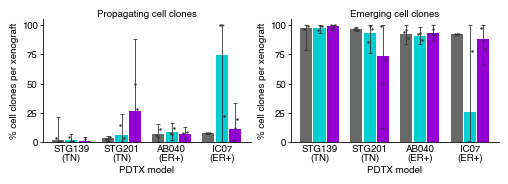

saved figS4B_amplicon_bargraph_num_propagating_emerging_per_mouse: 4.963 x 1.760 in


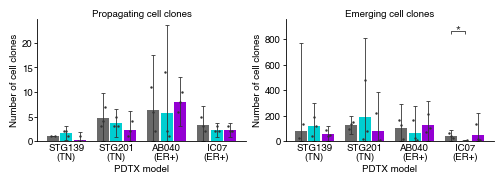

saved figS4BC_legend_cohorts: 0.682 x 0.404 in


<Figure size 68.2x40.4 with 0 Axes>

In [ ]:
# Bar graphs of propagating and emerging clones per mouse, as % of the mouse's clones and as numbers of clones
sns.reset_defaults()
fs.apply_style()

cohort_order = ["Untreated", "Paclitaxel", "Carboplatin"]
cohort_colours = {"Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
model_order = ["STG139", "STG201", "AB040", "IC07"]
clone_types = ["Propagating", "Emerging"]
BOX_GROUP_WIDTH = 0.8

def dodge_x(group_index, hue_index, n_hues):
    return group_index - BOX_GROUP_WIDTH / 2 + BOX_GROUP_WIDTH / n_hues * (hue_index + 0.5)

def draw_cohort_bars(ax, df, x, order, hue_order, bars, title, y="Percent", upper_bound=100.0):
    hi = float(df[y].max())
    for g, group in enumerate(order):
        for h, cohort in enumerate(hue_order):
            values = df.loc[(df[x] == group) & (df["Cohort"] == cohort), y].values
            if len(values) == 0:
                continue
            centre = dodge_x(g, h, len(hue_order))
            mean = values.mean()
            ax.bar(centre, mean, width=BOX_GROUP_WIDTH / len(hue_order) * 0.9, color=cohort_colours[cohort], linewidth=0)
            if len(values) > 1:
                half_width = scipy.stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
                low, high = max(mean - half_width, 0.0), mean + half_width
                if upper_bound is not None:
                    high = min(high, upper_bound)
                ax.errorbar(centre, mean, yerr=[[mean - low], [high - mean]], color="#333333", capsize=1.5,
                            linewidth=0.6, capthick=0.6)
                hi = max(hi, high)
            jitter = np.linspace(-0.04, 0.04, len(values)) if len(values) > 1 else np.zeros(1)
            ax.scatter(centre + jitter, values, s=3, color="#333333", linewidths=0, zorder=3)
    if hi == 0:
        hi = 1.0            

    levels = {}
    for group, _, _, _ in bars:
        levels[group] = levels.get(group, 0) + 1
    n_levels = max(levels.values(), default=0)
    step = hi * 0.13
    top = hi + step * (n_levels + 0.4) if n_levels else hi * 1.05
    ax.set_ylim(0, top)
    ax.set_yticks([tick for tick in mticker.MaxNLocator(nbins=5).tick_values(0, top)
                   if 0 <= tick <= min(top, upper_bound if upper_bound is not None else top)])

    drawn = {}
    for group, x_left, x_right, p in bars:
        level = drawn.get(group, 0)
        drawn[group] = level + 1
        fs.significance_bracket(ax, x_left, x_right, hi + step * (level + 0.5), p, tick=hi * 0.03)
    ax.set_title(title)
    ax.set(xlabel=None, ylabel=None)
    ax.spines[["top", "right"]].set_visible(False)

plot_df = clone_type_pct_df.reset_index()
plot_df.columns = [{"level_0": "Tumor", "level_1": "Cohort", "level_2": "Mouse"}.get(c, c) for c in plot_df.columns]
assert {"Tumor", "Cohort", "Mouse"} <= set(plot_df.columns)

for value, tests, unit, y_title, slug, panel, height in [
        ("% {}", clone_type_tests, "%", "% cell clones per xenograft", "pct", "figS4C", 1.769),
        ("{}", clone_count_tests, "clones", "Number of cell clones", "num", "figS4B", 1.760)]:
    width = 4.963
    fig = fs.new_panel(width, height)
    left = 0.46 if "\n" in y_title else 0.38
    gap, right, top, bottom = left + 0.02, 0.02, 0.14, 0.4
    panel_w = (width - left - gap - right) / 2
    axes = [fs.inch_axes(fig, left + k * (panel_w + gap), top, panel_w, height - top - bottom) for k in range(2)]
    for ax, clone_type in zip(axes, clone_types):
        column = value.format(clone_type)
        measure = f"% {clone_type}" if unit == "%" else f"Number of {clone_type.lower()} clones"
        bars = []
        for g, model in enumerate(model_order):
            for cohort in ["Paclitaxel", "Carboplatin"]:
                row = tests.loc[(tests["Tumor"] == model) & (tests["Measure"] == measure) & (tests["Comparison"] == f"{cohort} vs Untreated")].iloc[0]
                if row["p (Student's t, mice as replicates)"] < SIG_ALPHA:
                    bars.append((g, dodge_x(g, 0, 3), dodge_x(g, cohort_order.index(cohort), 3),
                                 row["p (Student's t, mice as replicates)"]))
        draw_cohort_bars(ax, plot_df, "Tumor", model_order, cohort_order, bars, f"{clone_type} cell clones",
                         y=column, upper_bound=100.0 if unit == "%" else None)
        ax.set_xticks(range(len(model_order)))
        ax.set_xticklabels([f"{model}\n({model_type[model]})" for model in model_order], linespacing=1.0)
        ax.tick_params(axis="x", length=0)
        ax.set_xlabel("PDTX model")          
        ax.set_ylabel(y_title, linespacing=1.0)
    fs.save_panel(fig, f"{panel}_amplicon_bargraph_{slug}_propagating_emerging_per_mouse")
    plt.show()

fs.legend_panel("figS4BC_legend_cohorts", 0.682, 0.404,
                [mpl.patches.Patch(color=colour, label=cohort) for cohort, colour in cohort_colours.items()],
                loc="center left", handlelength=0.8, handleheight=0.8, labelspacing=0.25)
plt.show()

saved figEV2B_amplicon_bargraph_pct_response_per_mouse: 3.607 x 2.617 in


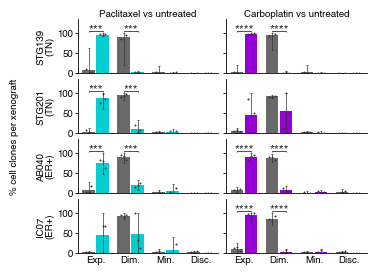

saved figEV2B_legend_cohorts: 0.750 x 0.342 in


<Figure size 75x34.2 with 0 Axes>

In [ ]:
# Bar graphs of % expanded, diminished, minimal change, and discrepant clones per mouse
sns.reset_defaults()
fs.apply_style()

RESPONSE_FIGURE_SIZE = (3.607, 2.617)
MOUSE_DOT_SIZE = 2                      # pt²
response_order = ["Expanded", "Diminished", "Minimal change", "Discrepant"]
response_short = {"Expanded": "Exp.", "Diminished": "Dim.", "Minimal change": "Min.", "Discrepant": "Disc."}
response_cohort_colours = {"Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}
response_model_order = ["STG139", "STG201", "AB040", "IC07"]
response_model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

plot_df = response_pct_df[[f"% {r}" for r in response_order]].rename(columns=lambda c: c[2:]).stack().rename("Percent").reset_index()
plot_df.columns = ["Tumor", "Drug", "Cohort", "Mouse", "Response", "Percent"]

width, height = RESPONSE_FIGURE_SIZE
left, right, top, bottom, column_gap, row_gap = 0.7, 0.02, 0.14, 0.14, 0.08, 0.06
fig = fs.new_panel(width, height)
panel_width = (width - left - right - column_gap) / 2
panel_height = (height - top - bottom - 3 * row_gap) / len(response_model_order)
bar_width = 0.8 / 2
for r, model in enumerate(response_model_order):
    for c, drug in enumerate(["Paclitaxel", "Carboplatin"]):
        ax = fs.inch_axes(fig, left + c * (panel_width + column_gap), top + r * (panel_height + row_gap),
                          panel_width, panel_height)
        df = plot_df.loc[(plot_df["Tumor"] == model) & (plot_df["Drug"] == drug)]
        tests = response_tests.loc[(response_tests["Tumor"] == model) & (response_tests["Comparison"] == f"{drug} vs Untreated")]
        for g, response in enumerate(response_order):
            centres = {}
            for h, cohort in enumerate(["Untreated", drug]):
                values = df.loc[(df["Response"] == response) & (df["Cohort"] == cohort), "Percent"].values
                x = g - 0.4 + bar_width * (h + 0.5)
                centres[cohort] = x
                if len(values) == 0:
                    continue
                mean = values.mean()
                ax.bar(x, mean, width=bar_width * 0.9, color=response_cohort_colours[cohort], linewidth=0)
                if len(values) > 1:
                    half = scipy.stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
                    low, high = max(mean - half, 0), min(mean + half, 100)
                    ax.errorbar(x, mean, yerr=[[mean - low], [high - mean]], color="#333333", capsize=1, linewidth=0.5, capthick=0.5)
                jitter = np.linspace(-bar_width * 0.2, bar_width * 0.2, len(values)) if len(values) > 1 else np.zeros(1)
                ax.scatter(x + jitter, values, s=MOUSE_DOT_SIZE, color="#333333", linewidths=0, zorder=3)
            measure = tests.loc[tests["Measure"] == f"% {response}"]
            if not measure.empty:
                fs.significance_bracket(ax, centres["Untreated"], centres[drug], 106,
                                        measure.iloc[0]["p (Student's t, mice as replicates)"], tick=4)
        ax.set_xlim(-0.5, len(response_order) - 0.5)
        ax.set_ylim(0, 135)
        ax.set_yticks([0, 50, 100])
        ax.tick_params(axis="y", labelleft=(c == 0))
        ax.set_xticks(range(len(response_order)))
        ax.set_xticklabels([response_short[resp] for resp in response_order] if r == len(response_model_order) - 1 else [])
        ax.tick_params(axis="x", length=0)
        ax.spines[["top", "right"]].set_visible(False)
        if r == 0:
            ax.set_title(f"{drug} vs untreated")
        if c == 0:
            ax.set_ylabel(f"{model}\n({response_model_type[model]})", labelpad=2, linespacing=1.0)

fs.fig_text(fig, 0.02, top + (height - top - bottom) / 2, "% cell clones per xenograft", rotation=90,
            va="center", ha="left")    # one line, short enough to stay clear of the legend placed above-left
fs.save_panel(fig, "figEV2B_amplicon_bargraph_pct_response_per_mouse")
plt.show()

response_legend_handles = [mpl.patches.Patch(color=colour, label=cohort) for cohort, colour in response_cohort_colours.items()]
fs.legend_panel("figEV2B_legend_cohorts", 0.75, 0.342, response_legend_handles, loc="center left",
                handlelength=0.8, handleheight=0.7, labelspacing=0.15)
plt.show()

In [ ]:
# Clonal diversity per mouse: Shannon entropy and Gini coefficient of clone size, and number of clones
diversity_cohorts = ["Primary", "Untreated", "Paclitaxel", "Carboplatin"]

def shannon_entropy_bits(values):
    shares = np.asarray(values, dtype=float)
    shares = shares[shares > 0] / shares.sum()
    return float(-(shares * np.log2(shares)).sum())

def gini_coefficient(values):
    ordered = np.sort(np.asarray(values, dtype=float))
    n = len(ordered)
    if n == 0 or ordered.sum() == 0:
        return np.nan
    return float(2 * np.sum(np.arange(1, n + 1) * ordered) / (n * ordered.sum()) - (n + 1) / n)

def mean_with_ci(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return values.mean(), np.nan, np.nan
    half_width = scipy.stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half_width, values.mean() + half_width

def compare_to_untreated(untreated_values, treated_values):
    u, t = np.asarray(untreated_values, dtype=float), np.asarray(treated_values, dtype=float)
    diff = t.mean() - u.mean()
    dof = len(u) + len(t) - 2
    pooled_sd = np.sqrt(((len(u) - 1) * u.var(ddof=1) + (len(t) - 1) * t.var(ddof=1)) / dof)
    if pooled_sd == 0:
        return diff, np.nan, np.nan, np.nan, np.nan    # no mouse-to-mouse variation in either cohort: not testable
    half_width = scipy.stats.t.ppf(0.975, dof) * pooled_sd * np.sqrt(1 / len(u) + 1 / len(t))
    hedges_g = diff / pooled_sd * (1 - 3 / (4 * (len(u) + len(t)) - 9))
    return diff, diff - half_width, diff + half_width, hedges_g, scipy.stats.ttest_ind(t, u).pvalue

clone_sizes = {}
for model, model_info in full_stats.items():
    clone_sizes[(model, "Primary", "1")] = [item["barcode info"]["primary_cells"] for item in model_info if item["barcode info"]["primary_cells"] > 0]
    for cohort in ["Untreated", "Paclitaxel", "Carboplatin"]:
        for i in range(0, 3):
            mouse = str(model_info[0]["secondary cohort info"][cohort]["mouse"][i])
            if model == "STG139" and cohort == "Untreated" and mouse == "3":
                continue
            sizes = [item["secondary cohort info"][cohort]["all_num_cells"][i] for item in model_info
                     if item["secondary cohort info"][cohort]["all_num_cells"][i] > 0]
            if sizes:
                clone_sizes[(model, cohort, mouse)] = sizes

clone_metrics = pd.DataFrame(
    [{"Tumor": m, "Cohort": c, "Mouse": mouse, "Number of clones": len(sizes),
      "Clone size entropy (bits)": shannon_entropy_bits(sizes), "Clone size Gini": gini_coefficient(sizes)}
     for (m, c, mouse), sizes in clone_sizes.items()]).set_index(["Tumor", "Cohort", "Mouse"])

for (model, cohort, mouse), sizes in clone_sizes.items():
    assert min(sizes) > 0, (model, cohort, mouse)
    column = seq_info[model]["Primary" if cohort == "Primary" else f"{cohort} {mouse}"]
    detected = np.sort(column[column > 0].values.astype(float))
    assert np.allclose(np.sort(sizes), detected), (model, cohort, mouse)
    shares = detected / detected.sum()
    assert np.isclose(clone_metrics.loc[(model, cohort, mouse), "Clone size entropy (bits)"], -(shares * np.log2(shares)).sum()), (model, cohort, mouse)

# The clone counts must match the clone type table's
secondary_counts = clone_metrics.drop(index="Primary", level="Cohort")["Number of clones"]
expected = summary_df_v6[("", "", "Unique clones per replicate")]
expected.index = expected.index.set_levels(expected.index.levels[2].str.replace("Replicate ", ""), level=2)
assert (secondary_counts.sort_index() == expected.reindex(secondary_counts.index).sort_index()).all()

summary_rows, test_rows = [], []
def summarise_and_test(model, metric, values_by_cohort):
    for cohort, values in values_by_cohort.items():
        mean, ci_low, ci_high = mean_with_ci(values)
        summary_rows.append({"Tumor": model, "Metric": metric, "Cohort": cohort,
                             "Mice": len(values), "Mean": mean, "95% CI low": ci_low, "95% CI high": ci_high})
    for cohort in ["Paclitaxel", "Carboplatin"]:
        if cohort in values_by_cohort and "Untreated" in values_by_cohort:
            diff, ci_low, ci_high, g, p = compare_to_untreated(values_by_cohort["Untreated"], values_by_cohort[cohort])
            test_rows.append({"Tumor": model, "Metric": metric, "Comparison": f"{cohort} vs Untreated",
                              "Mice (untreated, treated)": f"{len(values_by_cohort['Untreated'])}, {len(values_by_cohort[cohort])}",
                              "Untreated mean": np.mean(values_by_cohort["Untreated"]), "Treated mean": np.mean(values_by_cohort[cohort]),
                              "Difference (treated - untreated)": diff, "95% CI low": ci_low, "95% CI high": ci_high,
                              "Hedges' g": g, "p (two-tailed Student's t)": p,
                              "Significant": bool(p < SIG_ALPHA) if not np.isnan(p) else "not testable"})

SIG_ALPHA = 0.05
for model in clone_metrics.index.get_level_values("Tumor").unique():
    for metric in ["Clone size entropy (bits)", "Clone size Gini", "Number of clones"]:
        model_df = clone_metrics.loc[model, metric]
        summarise_and_test(model, metric, {c: model_df.loc[c].values for c in diversity_cohorts if c in model_df.index})

diversity_summary = pd.DataFrame(summary_rows)
diversity_tests = pd.DataFrame(test_rows)
with pd.ExcelWriter("../data_files/amplicon_data/amplicon_clonal_diversity_entropy_gini.xlsx") as writer:
    clone_metrics.to_excel(writer, sheet_name="Clone size per mouse")
    diversity_summary.to_excel(writer, sheet_name="Cohort means", index=False)
    diversity_tests.to_excel(writer, sheet_name="Treated vs untreated", index=False)

display(diversity_tests.round(4))

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/3060404067.py:101: PerformanceWarning: indexing past lexsort depth may impact performance.
  model_df = clone_metrics.loc[model, metric]


,Tumor,Metric,Comparison,"Mice (untreated, treated)",Untreated mean,Treated mean,Difference (treated - untreated),95% CI low,95% CI high,Hedges' g,p (two-tailed Student's t),Significant
0,AB040,Clone size entropy (bits),Paclitaxel vs Untreated,"3, 3",2.5801,2.9048,0.3247,-1.2881,1.9375,0.3651,0.6060,False
1,AB040,Clone size entropy (bits),Carboplatin vs Untreated,"3, 3",2.5801,2.9105,0.3304,-1.3015,1.9623,0.3672,0.6040,False
2,AB040,Clone size Gini,Paclitaxel vs Untreated,"3, 3",0.8781,0.6701,-0.2079,-0.6001,0.1842,-0.9617,0.2149,False
3,AB040,Clone size Gini,Carboplatin vs Untreated,"3, 3",0.8781,0.9116,0.0335,-0.0188,0.0858,1.1607,0.1502,False
4,AB040,Number of clones,Paclitaxel vs Untreated,"3, 3",108.6667,71.6667,-37.0000,-234.3404,160.3404,-0.3400,0.6302,False
5,AB040,Number of clones,Carboplatin vs Untreated,"3, 3",108.6667,138.6667,30.0000,-146.0557,206.0557,0.3090,0.6608,False
6,IC07,Clone size entropy (bits),Paclitaxel vs Untreated,"3, 3",1.6723,0.8369,-0.8354,-2.7454,1.0747,-0.7932,0.2914,False
7,IC07,Clone size entropy (bits),Carboplatin vs Untreated,"3, 3",1.6723,1.7617,0.0895,-1.9320,2.1109,0.0803,0.9081,False
8,IC07,Clone size Gini,Paclitaxel vs Untreated,"3, 3",0.8515,0.5378,-0.3137,-0.7319,0.1045,-1.3606,0.1057,False
9,IC07,Clone size Gini,Carboplatin vs Untreated,"3, 3",0.8515,0.8229,-0.0286,-0.2585,0.2012,-0.2260,0.7468,False


saved figS3C_amplicon_diversity_clone_size_entropy_bargraph: 3.798 x 2.327 in


/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1564593401.py:43: PerformanceWarning: indexing past lexsort depth may impact performance.
  mice = clone_metrics.loc[(model, cohort), metric].values


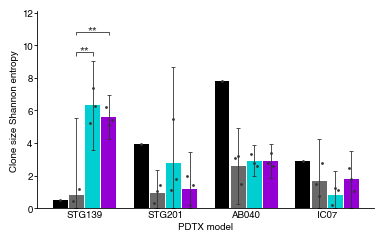

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_59197/1564593401.py:43: PerformanceWarning: indexing past lexsort depth may impact performance.
  mice = clone_metrics.loc[(model, cohort), metric].values


saved figS3D_amplicon_diversity_clone_size_gini_bargraph: 3.832 x 2.327 in


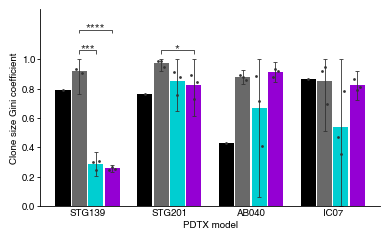

saved figS3CD_legend_cohorts: 0.687 x 0.505 in


<Figure size 68.7x50.5 with 0 Axes>

In [ ]:
# Bar graphs of each clonal diversity metric
sns.reset_defaults()
fs.apply_style()

bar_colours = {"Primary": "black", "Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}
bar_model_order = ["STG139", "STG201", "AB040", "IC07"]
metric_upper_bounds = {"Clone size Gini": 1.0}
BAR_GROUP_WIDTH = 0.8

def draw_diversity_bars(ax, metric, ylabel):
    width = BAR_GROUP_WIDTH / len(diversity_cohorts)
    upper_bound = metric_upper_bounds.get(metric, np.inf)

    drawn = {}
    for m, model in enumerate(bar_model_order):
        for b, cohort in enumerate(diversity_cohorts):
            row = diversity_summary.loc[(diversity_summary["Tumor"] == model) & (diversity_summary["Metric"] == metric)
                                        & (diversity_summary["Cohort"] == cohort)]
            if row.empty:
                continue
            row = row.iloc[0]
            x = m - BAR_GROUP_WIDTH / 2 + width * (b + 0.5)
            ax.bar(x, row["Mean"], width=width * 0.92, color=bar_colours[cohort], linewidth=0, label=cohort if m == 0 else None)
            bar_top = row["Mean"]
            if not np.isnan(row["95% CI low"]):
                low, high = max(row["95% CI low"], 0.0), min(row["95% CI high"], upper_bound)
                ax.errorbar(x, row["Mean"], yerr=[[row["Mean"] - low], [high - row["Mean"]]], color="#333333",
                            capsize=1.5, linewidth=0.6, capthick=0.6)
                bar_top = high
            mice = clone_metrics.loc[(model, cohort), metric].values
            jitter = np.linspace(-width * 0.18, width * 0.18, len(mice)) if len(mice) > 1 else np.zeros(1)
            ax.scatter(x + jitter, mice, s=4, color="#333333", zorder=3, linewidths=0)
            drawn[(model, cohort)] = (x, max(bar_top, float(np.max(mice))))
    data_top = max(top for _, top in drawn.values())

    step = data_top * 0.14
    axis_top = data_top
    for model in bar_model_order:
        level = 0
        for drug in ["Paclitaxel", "Carboplatin"]:
            test = diversity_tests.loc[(diversity_tests["Tumor"] == model) & (diversity_tests["Metric"] == metric)
                                       & (diversity_tests["Comparison"] == f"{drug} vs Untreated")]
            if test.empty or not test.iloc[0]["p (two-tailed Student's t)"] < SIG_ALPHA:
                continue
            (x_left, _), (x_right, _) = drawn[(model, "Untreated")], drawn[(model, drug)]
            local_top = max(top for (mod, _), (_, top) in drawn.items() if mod == model)
            line_y = local_top + data_top * 0.06 + level * step
            fs.significance_bracket(ax, x_left, x_right, line_y, test.iloc[0]["p (two-tailed Student's t)"],
                                    tick=data_top * 0.025)
            axis_top = max(axis_top, line_y + step * 0.8)
            level += 1

    ax.set_ylim(0, axis_top * 1.02)
    ax.set_yticks([tick for tick in ax.get_yticks() if 0 <= tick <= min(upper_bound, axis_top * 1.02)])
    ax.set_xticks(range(len(bar_model_order)))
    ax.set_xticklabels(bar_model_order)
    ax.tick_params(axis="x", length=0)
    ax.set_xlabel("PDTX model")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)

plots = [("Clone size entropy (bits)", "Clone size Shannon entropy", "clone_size_entropy", "figS3C", 3.798),
         ("Clone size Gini", "Clone size Gini coefficient", "clone_size_gini", "figS3D", 3.832)]

for metric, ylabel, slug, panel, width in plots:
    fig = fs.new_panel(width, 2.327)
    ax = fs.inch_axes(fig, 0.4, 0.06, width - 0.4 - 0.03, 2.327 - 0.06 - 0.3)
    draw_diversity_bars(ax, metric, ylabel)
    fs.save_panel(fig, f"{panel}_amplicon_diversity_{slug}_bargraph")
    plt.show()

fs.legend_panel("figS3CD_legend_cohorts", 0.687, 0.505,
                [mpl.patches.Patch(color=colour, label=cohort) for cohort, colour in bar_colours.items()],
                loc="center left", handlelength=0.8, handleheight=0.8, labelspacing=0.25)
plt.show()

paired: 4.31 x 7.98 in, facets 0.57 x 0.44 in


saved figEV2C_amplicon_clone_size_untreated_vs_treated_paired: 4.310 x 7.979 in


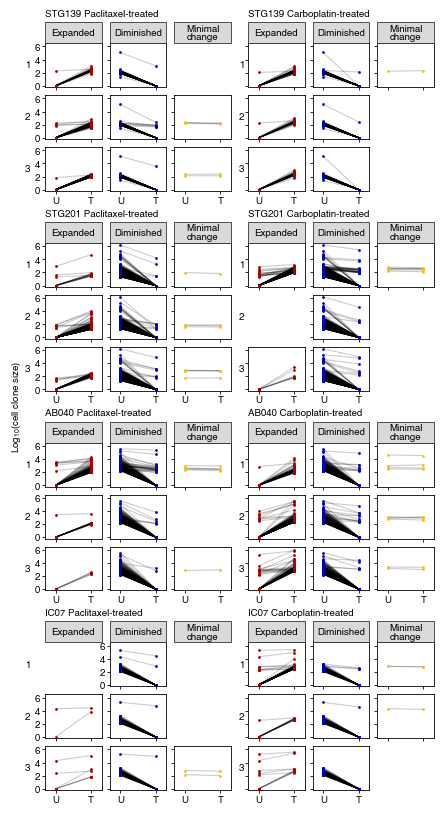

In [ ]:
# Clone size in the untreated cohort vs in each treated mouse
sns.reset_defaults()
fs.apply_style()

paired_responses = ["Expanded", "Diminished", "Minimal change"]
paired_colours = {"Expanded": "#a70000", "Diminished": "#0000b3", "Minimal change": "#F5BE19"}
paired_model_order = ["STG139", "STG201", "AB040", "IC07"]
paired_drugs = ["Paclitaxel", "Carboplatin"]

paired_rows = []
for model, model_info in full_stats.items():
    for item in model_info:
        row_cohort = item["secondary cohort info"]
        untreated = row_cohort["Untreated"]
        untreated_nonzero = [cells for cells in untreated["all_num_cells"] if cells > 0]
        untreated_size = statistics.mean(untreated_nonzero) if untreated_nonzero else 0      # as avg_nonzero is computed
        assert untreated_size == untreated["avg_nonzero"], (model, item["barcode info"]["barcode"])
        for drug in paired_drugs:
            for i in range(0, 3):
                treated_cells = row_cohort[drug]["all_num_cells"][i]
                if treated_cells == 0 and not untreated_nonzero:
                    continue                                    # in neither the untreated mice nor this mouse
                response = "Diminished" if treated_cells == 0 else row_cohort[drug]["all_treated_responses"][i]
                paired_rows.append({"Tumor": model, "Drug": drug, "Mouse": str(row_cohort[drug]["mouse"][i]),
                                    "Barcode": item["barcode info"]["barcode"], "Response": response,
                                    "Untreated size": untreated_size, "Treated size": treated_cells})
paired_clone_sizes = pd.DataFrame(paired_rows)
paired_clone_sizes["Change in clone size"] = paired_clone_sizes["Treated size"] - paired_clone_sizes["Untreated size"]
assert set(paired_clone_sizes["Response"]) <= set(paired_responses), set(paired_clone_sizes["Response"])

stg139_untreated_mice = [str(m) for m in full_stats["STG139"][0]["secondary cohort info"]["Untreated"]["mouse"]]
assert all(item["secondary cohort info"]["Untreated"]["all_num_cells"][stg139_untreated_mice.index("3")] == 0
           for item in full_stats["STG139"])

# Every model x drug has treated mice 1, 2 and 3
paired_mice = ["1", "2", "3"]
assert all([str(m) for m in full_stats[model][0]["secondary cohort info"][drug]["mouse"]] == paired_mice
           for model in paired_model_order for drug in paired_drugs)

PAIRED_X_PAD = 0.3     

def draw_paired_facet(ax, df, response, y_max, dot_size=4, x_labels=True, y_labels=True):
    y_untreated, y_treated = np.log10(df["Untreated size"] + 1), np.log10(df["Treated size"] + 1)
    segments = np.stack([np.column_stack([np.zeros(len(df)), y_untreated]), np.column_stack([np.ones(len(df)), y_treated])], axis=1)
    ax.add_collection(mpl.collections.LineCollection(segments, colors="black", linewidths=0.8, alpha=0.2))
    ax.scatter(np.zeros(len(df)), y_untreated, s=dot_size, color=paired_colours[response], linewidths=0, zorder=3)
    ax.scatter(np.ones(len(df)), y_treated, s=dot_size, color=paired_colours[response], linewidths=0, zorder=3)
    ax.set_xlim(-PAIRED_X_PAD, 1 + PAIRED_X_PAD)
    ax.set_ylim(-0.2, y_max)
    ax.set_yticks(range(0, int(y_max) + 1, 2))
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["U", "T"] if x_labels else [])                 
    ax.tick_params(axis="y", labelleft=y_labels)

def strip_title(fig, left, top, width, height, text):
    fig_w, fig_h = fig.get_size_inches()
    fig.add_artist(mpl.patches.Rectangle((left / fig_w, 1 - (top + height) / fig_h), width / fig_w, height / fig_h,
                                         transform=fig.transFigure, facecolor="#d9d9d9", edgecolor="#333333",
                                         linewidth=fs.LINE))
    fs.fig_text(fig, left + width / 2, top + height / 2, text, ha="center", va="center", linespacing=1.0)

STRIP_LABELS = {"Expanded": "Expanded", "Diminished": "Diminished", "Minimal change": "Minimal\nchange"}

def paired_figure(width=4.31, height=7.979, edge=0.02, title_w=0.12, text_gap=0.03, number_w=0.06, ticks_w=0.11,
                  block_gap=0.08, facet_gap=0.08, title_h=0.1, strip_h=0.21, mouse_gap=0.08, x_labels_h=0.13,
                  row_gap=0.05, right_edge=0.05):

    y_max = np.log10(paired_clone_sizes[["Untreated size", "Treated size"]].max().max() + 1) * 1.05
    fig = fs.new_panel(width, height)
    left = edge + title_w + text_gap
    facets_x = [number_w + text_gap + ticks_w, number_w + text_gap]           # from each block's left edge
    facet_w = (width - left - right_edge - sum(facets_x) - block_gap
               - len(paired_drugs) * (len(paired_responses) - 1) * facet_gap) / (len(paired_drugs) * len(paired_responses))
    row_h = (height - 2 * edge - (len(paired_model_order) - 1) * row_gap) / len(paired_model_order)
    facet_h = (row_h - title_h - text_gap - strip_h - (len(paired_mice) - 1) * mouse_gap - x_labels_h) / len(paired_mice)

    for r, model in enumerate(paired_model_order):
        top = edge + r * (row_h + row_gap)
        strips_top = top + title_h + text_gap
        x_block = left
        for d, drug in enumerate(paired_drugs):
            x_facets = x_block + facets_x[d]
            fs.fig_text(fig, x_facets, top, f"{model} {drug}-treated", ha="left", va="top")
            block = paired_clone_sizes.loc[(paired_clone_sizes["Tumor"] == model) & (paired_clone_sizes["Drug"] == drug)]
            for f, response in enumerate(paired_responses):
                if (block["Response"] == response).any():
                    strip_title(fig, x_facets + f * (facet_w + facet_gap), strips_top, facet_w, strip_h,
                                STRIP_LABELS[response])
            for m, mouse in enumerate(paired_mice):
                facet_top = strips_top + strip_h + m * (facet_h + mouse_gap)
                fs.fig_text(fig, x_block, facet_top + facet_h / 2, mouse, ha="left", va="center")
                mouse_clones = block.loc[block["Mouse"] == mouse]
                present = [response for response in paired_responses if (mouse_clones["Response"] == response).any()]
                for f, response in enumerate(paired_responses):
                    if response not in present:
                        continue                                                  # graphs only where the mouse has clones
                    ax = fs.inch_axes(fig, x_facets + f * (facet_w + facet_gap), facet_top, facet_w, facet_h)
                    draw_paired_facet(ax, mouse_clones.loc[mouse_clones["Response"] == response], response, y_max,
                                      x_labels=(m == len(paired_mice) - 1), y_labels=(d == 0 and response == present[0]))
            x_block = x_facets + len(paired_responses) * facet_w + (len(paired_responses) - 1) * facet_gap + block_gap
    fs.fig_text(fig, edge, height / 2, "Log$_{10}$(cell clone size)", rotation=90, ha="left", va="center")
    print(f"paired: {width:.2f} x {height:.2f} in, facets {facet_w:.2f} x {facet_h:.2f} in")
    return fig

fig = paired_figure()
fs.save_panel(fig, "figEV2C_amplicon_clone_size_untreated_vs_treated_paired")
plt.show()

saved figEV2D_amplicon_change_in_clone_size_bargraph: 3.458 x 3.042 in


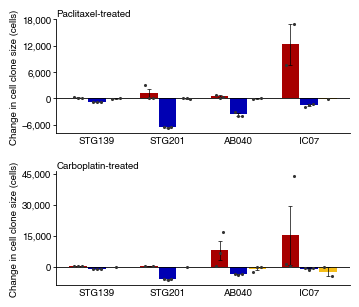

saved figEV2CD_legend_responses: 2.400 x 0.124 in


<Figure size 240x12.4 with 0 Axes>

Mice  Mean change (cells)      SEM  \
Tumor  Drug        Response                                             
AB040  Carboplatin Diminished         3              -3577.1    129.4   
                   Expanded           3               7990.4   4687.4   
                   Minimal change     3               -923.8    752.6   
       Paclitaxel  Diminished         3              -3650.3    309.6   
                   Expanded           3                431.0    223.2   
                   Minimal change     2                 37.0    121.9   
IC07   Carboplatin Diminished         3               -835.0    437.2   
                   Expanded           3              15239.8  14225.3   
                   Minimal change     2              -2322.5   2218.0   
       Paclitaxel  Diminished         3              -1551.0    196.2   
                   Expanded           2              12266.2   4608.3   
                   Minimal change     1                -82.0      NaN   
STG139 Carboplatin Diminished         3               -885.2      2.5   
                   Expanded           3                235.0     30.5   
                   Minimal change     1                 35.5      NaN   
       Paclitaxel  Diminished         3               -887.2     12.1   
                   Expanded           3                164.6     43.9   
                   Minimal change     2                -12.7     29.7   
STG201 Carboplatin Diminished         3              -6123.4    142.7   
                   Expanded           2                387.6    151.2   
                   Minimal change     1                -38.8      NaN   
       Paclitaxel  Diminished         3              -6576.9     81.5   
                   Expanded           3               1141.5   1007.2   
                   Minimal change     3                -25.8     13.2   

                                   Mouse 1  Mouse 2  Mouse 3  
Tumor  Drug        Response                                   
AB040  Carboplatin Diminished      -3592.8  -3793.1  -3345.5  
                   Expanded          564.8   6747.4  16659.0  
                   Minimal change  -2421.0    -40.5   -310.0  
       Paclitaxel  Diminished      -3031.2  -3946.8  -3972.9  
                   Expanded          874.1    162.2    256.7  
                   Minimal change    -84.9      NaN    158.9  
IC07   Carboplatin Diminished       -391.3  -1709.3   -404.4  
                   Expanded         1554.2    481.6  43683.7  
                   Minimal change   -104.4  -4540.5      NaN  
       Paclitaxel  Diminished      -1904.9  -1520.7  -1227.3  
                   Expanded            NaN   7657.9  16874.5  
                   Minimal change      NaN      NaN    -82.0  
STG139 Carboplatin Diminished       -890.0   -884.2   -881.4  
                   Expanded          175.8    277.4    251.8  
                   Minimal change     35.5      NaN      NaN  
       Paclitaxel  Diminished       -878.6   -911.0   -871.9  
                   Expanded          250.8    106.8    136.2  
                   Minimal change      NaN    -42.5     17.0  
STG201 Carboplatin Diminished      -5940.9  -6404.7  -6024.6  
                   Expanded          236.3      NaN    538.8  
                   Minimal change    -38.8      NaN      NaN  
       Paclitaxel  Diminished      -6556.9  -6727.0  -6446.8  
                   Expanded         3155.8    111.9    156.9  
                   Minimal change    -26.9     -2.5    -48.1

In [ ]:
# Bar graph of the change in clone size per model and response
sns.reset_defaults()
fs.apply_style()

change_model_order = ["STG139", "STG201", "AB040", "IC07"]
CHANGE_DOT_SIZE = 5                     # pt²

mouse_change = (paired_clone_sizes.groupby(["Tumor", "Drug", "Response", "Mouse"])["Change in clone size"]
                .agg(["count", "mean"]).rename(columns={"count": "Clones", "mean": "Mean change (cells)"}).reset_index())
change_rows = []
for (model, drug, response), df in mouse_change.groupby(["Tumor", "Drug", "Response"]):
    mice = df["Mean change (cells)"]
    change_rows.append({"Tumor": model, "Drug": drug, "Response": response, "Mice": len(mice), "Mean change (cells)": mice.mean(),
                        "SEM": mice.std(ddof=1) / np.sqrt(len(mice)) if len(mice) > 1 else np.nan,
                        **{f"Mouse {mouse}": value for mouse, value in zip(df["Mouse"], mice)}})
change_summary = pd.DataFrame(change_rows).set_index(["Tumor", "Drug", "Response"])

def draw_change_bars(ax, drug):
    bar_width = 0.8 / len(paired_responses)
    extent = [0]                                                       
    for g, model in enumerate(change_model_order):
        for h, response in enumerate(paired_responses):
            if (model, drug, response) not in change_summary.index:
                continue
            row = change_summary.loc[(model, drug, response)]
            mice = mouse_change.loc[(mouse_change["Tumor"] == model) & (mouse_change["Drug"] == drug)
                                    & (mouse_change["Response"] == response), "Mean change (cells)"].values
            x = g - 0.4 + bar_width * (h + 0.5)
            mean, sem = row["Mean change (cells)"], row["SEM"]
            ax.bar(x, mean, width=bar_width * 0.92, color=paired_colours[response], linewidth=0)
            if not np.isnan(sem):
                ax.errorbar(x, mean, yerr=sem, color="black", capsize=1.5, linewidth=0.5, capthick=0.5)
                extent += [mean - sem, mean + sem]
            jitter = np.linspace(-bar_width * 0.2, bar_width * 0.2, len(mice)) if len(mice) > 1 else np.zeros(1)
            ax.scatter(x + jitter, mice, s=CHANGE_DOT_SIZE, color="#333333", linewidths=0, zorder=3)
            extent += [mean, *mice]
    low, high = min(extent), max(extent)
    ax.set_ylim(low - 0.05 * (high - low), high + 0.05 * (high - low))
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xticks(range(len(change_model_order)))
    ax.set_xticklabels(change_model_order)
    ax.tick_params(axis="x", length=0, pad=2)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda value, pos: f"{value:,.0f}".replace("-", "\u2212")))
    ax.set_title(f"{drug}-treated", loc="left")
    ax.spines[["top", "right"]].set_visible(False)

FIG_W, FIG_H = 3.458, 3.042
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, gap, bottom = 0.5, 0.02, 0.24, 0.38, 0.14
panel_h = (FIG_H - top - gap - bottom) / 2
axes = [fs.inch_axes(fig, left, top + k * (panel_h + gap), FIG_W - left - right, panel_h) for k in range(2)]
for ax, drug in zip(axes, ["Paclitaxel", "Carboplatin"]):
    draw_change_bars(ax, drug)
    ax.set_ylabel("Change in cell clone size (cells)", labelpad=2)
fs.save_panel(fig, "figEV2D_amplicon_change_in_clone_size_bargraph")
plt.show()

fs.legend_panel("figEV2CD_legend_responses", 2.4, 0.124,
                [mpl.patches.Patch(color=paired_colours[r], label=r) for r in ["Diminished", "Expanded", "Minimal change"]],
                ncol=3, loc="center left", handlelength=0.8, handleheight=0.7, columnspacing=1.0)
plt.show()

change_summary.to_csv("../data_files/amplicon_data/amplicon_change_in_clone_size_by_response.csv")
change_summary.round(1)

saved figS4A_amplicon_AB040_prop_trans_emerg_clone_size_line_graphs: 7.996 x 1.270 in


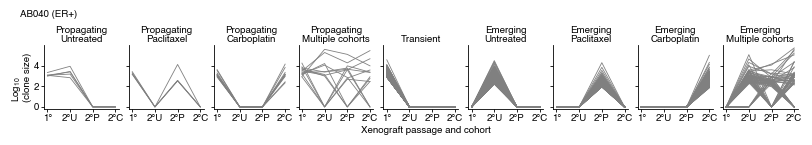

saved figS4A_amplicon_IC07_prop_trans_emerg_clone_size_line_graphs: 7.996 x 1.270 in


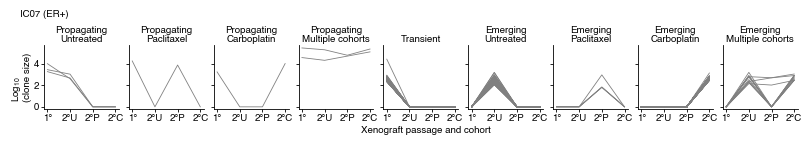

saved figS4A_amplicon_STG139_prop_trans_emerg_clone_size_line_graphs: 6.220 x 1.270 in


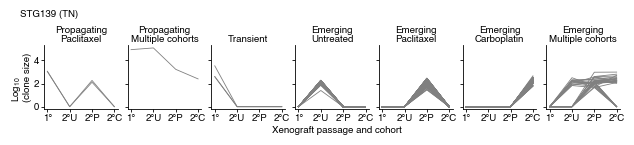

saved figS4A_amplicon_STG201_prop_trans_emerg_clone_size_line_graphs: 7.108 x 1.270 in


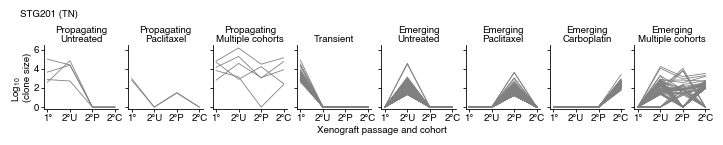

In [ ]:
# Create line graphs for number of cells with each barcode in primary and each secondary cohort for propagating, emerging, and transient clones

fs.apply_style()

model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
LINE_ROW_H, LINE_GAP = 1.27, 0.1                                # inches, as placed on the page
LINE_ROW_W = {"STG139": 6.220, "STG201": 7.108, "AB040": 7.996, "IC07": 7.996}
LINE_LEFT, LINE_TOP, LINE_BOTTOM = 0.36, 0.36, 0.27
models = ["AB040", "IC07", "STG139", "STG201"]
stats_data_with_multi = []

for model in models:
    model_info = seq_info[model]
    model_info = model_info.replace(0, np.nan).dropna(how="all")
    model_info["Untreated"] = model_info[["Untreated 1", "Untreated 2", "Untreated 3"]].mean(axis=1)
    model_info["Paclitaxel"] = model_info[["Paclitaxel 1", "Paclitaxel 2", "Paclitaxel 3"]].mean(axis=1)
    model_info["Carboplatin"] = model_info[["Carboplatin 1", "Carboplatin 2", "Carboplatin 3"]].mean(axis=1)
    model_info = model_info[["Primary", "Untreated", "Paclitaxel", "Carboplatin"]]

    primary_clones = model_info["Primary"].notna()
    secondary_clones = model_info[["Untreated", "Paclitaxel", "Carboplatin"]].notna().any(axis=1)
    secondary_clones_multi_cohort = model_info[["Untreated", "Paclitaxel", "Carboplatin"]].notna().sum(axis=1) >= 2
    secondary_clones_untreated = model_info["Untreated"].notna()
    secondary_clones_pac = model_info["Paclitaxel"].notna()
    secondary_clones_carb = model_info["Carboplatin"].notna()

    propagating_untreated = model_info[primary_clones & secondary_clones_untreated & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_pac = model_info[primary_clones & secondary_clones_pac & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_carb = model_info[primary_clones & secondary_clones_carb & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_multi = model_info[primary_clones & secondary_clones_multi_cohort].fillna(1).apply(np.log10)

    transient = model_info[primary_clones & ~secondary_clones].fillna(1).apply(np.log10)

    emerging_untreated = model_info[~primary_clones & secondary_clones_untreated & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_pac = model_info[~primary_clones & secondary_clones_pac & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_carb = model_info[~primary_clones & secondary_clones_carb & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_multi = model_info[~primary_clones & secondary_clones_multi_cohort].fillna(1).apply(np.log10)

    plot_data = [
        (propagating_untreated, "Propagating\nUntreated"),
        (propagating_pac, "Propagating\nPaclitaxel"), 
        (propagating_carb, "Propagating\nCarboplatin"), 
        (propagating_multi, "Propagating\nMultiple cohorts"),
        (transient, "Transient"),
        (emerging_untreated, "Emerging\nUntreated"),
        (emerging_pac, "Emerging\nPaclitaxel"),
        (emerging_carb, "Emerging\nCarboplatin"),
        (emerging_multi, "Emerging\nMultiple cohorts")
    ]

    for (df, title) in plot_data:
        stats_data_with_multi.append({
            "Model": model, 
            "Condition": title.replace("\n", " "),
            "Number of clones": df.shape[0]
        })

    valid_plots = [(df, title) for df, title in plot_data if not df.empty]

    n_plots = len(valid_plots)

    width = LINE_ROW_W[model]
    graph_w = (width - LINE_LEFT - 0.1 - (n_plots - 1) * LINE_GAP) / n_plots
    fig = fs.new_panel(width, LINE_ROW_H)
    plot_h = LINE_ROW_H - LINE_TOP - LINE_BOTTOM
    axes = fs.inch_grid(fig, LINE_LEFT, LINE_TOP, 1, n_plots, graph_w, plot_h, LINE_GAP, 0)[0]
    for ax in axes[1:]:
        ax.sharey(axes[0])

    for i, (df, title) in enumerate(valid_plots):
        ax = axes[i]
        for _, clone in df.iterrows():
            ax.plot(range(4), clone.values, color="grey", linewidth=0.6)
        ax.set_title(title, linespacing=1.0)
        ax.minorticks_off()
        ax.set_xticks([0, 1, 2, 3])
        ax.set_xticklabels(["1°", "2°U", "2°P", "2°C"])
        ax.set_xlim(-0.15, 3.15)
        ax.tick_params(axis="y", labelleft=(i == 0))
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    axes[0].set_ylim(bottom=-0.2)
    axes[0].yaxis.set_major_locator(mticker.MultipleLocator(2))

    fs.fig_text(fig, 0.12, 0.01, f"{model} ({model_type[model]})", ha="left", va="top")   # clear of the panel letter
    fs.fig_text(fig, LINE_LEFT + (width - LINE_LEFT) / 2, LINE_ROW_H - 0.01, "Xenograft passage and cohort",
                ha="center", va="bottom")
    fs.fig_text(fig, 0.02, LINE_TOP + plot_h / 2, "Log$_{10}$\n(clone size)", rotation="vertical",
                ha="left", va="center", linespacing=1.0)
    fs.save_panel(fig, f"figS4A_amplicon_{model}_prop_trans_emerg_clone_size_line_graphs")
    plt.show()

stats_data_with_multi_df = pd.DataFrame(stats_data_with_multi)
stats_data_with_multi_df.to_csv("../data_files/amplicon_data/clone_count_prop_emerg_trans_by_cohort_per_figS2.csv", index=False)